# BT2102 Assignment 3: Beijing property, all visualisations (data-driven)

Level 1: **What is the best investment strategy to maximise returns in Beijing properties?**

| Section | Level-2 question |
|---|---|
| D | What is the current state of the market and where is buyer interest strongest? |
| P1 | What property characteristics should investors target? |
| P2 | Which districts show the strongest and most consistent appreciation? |
| R | Which districts and property types carry the most risk? |

**Every chart is drawn from the data when the notebook runs.** Titles, highlighted groups, axis ranges,
ticks, colour scales and label positions are computed from the numbers, so they stay correct if the input
changes. Charts are shown inline from the live figure and saved to `charts_from_data/`.
The older `charts/` folder (pre-rendered images) is not read or written.

**Data rules** (the numbers behind each are printed in section 0):
1. Years 2012-2017 only (other years have too few trades). Ladder ratio > 1 removed as errors.
2. Prices are **median price per m²** (CNY). Growth = CAGR between yearly medians unless stated.
3. District names come from the district codes, checked against official boundaries by point-in-polygon.
4. DOM is only analysed from the month it starts being recorded properly (found from the data), so DOM charts use 2017.
5. Followers grow with the platform, so follower comparisons use 2017 trades only.

In [1]:
# CONFIG: every input path lives here. Repo-relative paths resolve from this notebook's folder.
from pathlib import Path

REPO = Path("../..").resolve()
MAIN_CSV = REPO / "data" / "processed" / "BeijingHousingPrices_featured.csv"   # output of src/featureengineering.py
RAW_XLSX = REPO / "data" / "raw" / "BeijingHousingPrices.xlsx"                 # only for the DOM column
YEARBOOK_DIR = Path(r"C:\Users\kalen\Downloads")                              # seven district_*.csv tables + manifest.json
GEOJSON = Path("beijing_districts.geojson")
OUT = Path("charts_from_data")                                                 # new charts; charts/ is left untouched
for p in [MAIN_CSV, RAW_XLSX, YEARBOOK_DIR / "manifest.json", GEOJSON]:
    assert p.exists(), f"missing input: {p}"

In [2]:
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.dates import AutoDateLocator, DateFormatter
from matplotlib.ticker import FixedLocator, NullLocator
from matplotlib.transforms import Bbox, blended_transform_factory
from shapely import STRtree
from shapely.geometry import Point, box, shape
from shapely.ops import unary_union

import bt2102_style as bs

sys.path.insert(0, str(REPO / "src"))
from featureengineering import CENTER_LAT, CENTER_LNG   # the point distance_to_center_km is measured from

bs.setup()
OUT.mkdir(exist_ok=True)
SRC = "Lianjia transactions, 2012-2017"
BASE, END = 2012, 2017
YEARS = list(range(BASE, END + 1))
N_YRS = END - BASE
CENTRE = (CENTER_LNG, CENTER_LAT)
INDEX_BASE = 2015                      # P2a: index base year, the last year before the 2016-17 boom
POLICY = pd.Timestamp("2017-03-17")   # Beijing "3.17" purchase curbs (higher down payments, shorter loans)
MIN_DISTRICT_TRADES = 100              # a district needs this many trades in both BASE and END to be ranked
pd.set_option("display.width", 160)


def publish(fig, name, source):
    """Add the source line, shrink any text that runs off the figure, keep the axes clear of the title block and
    the source line, then save to OUT and show the live figure."""
    src_t = fig.text(0.04, 0.025, f"Source: {source}", fontsize=10, color=bs.MUTED, va="bottom")
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    for t in fig.texts:
        while t.get_window_extent(r).x1 > fig.bbox.width * 0.985 and t.get_fontsize() > 8:
            t.set_fontsize(t.get_fontsize() - 0.5)
    H, gap = fig.bbox.height, 6
    for _ in range(3):
        fig.canvas.draw()
        boxes = [a.get_tightbbox(r) for a in fig.axes]
        head = [t.get_window_extent(r).y0 for t in fig.texts if t.get_position()[1] >= 0.8]
        d_top = max(0, max(b.y1 for b in boxes) - (min(head) - gap)) / H if head else 0
        d_bot = max(0, src_t.get_window_extent(r).y1 + gap - min(b.y0 for b in boxes)) / H
        if d_top < 1e-3 and d_bot < 1e-3:
            break
        for a in fig.axes:
            p = a.get_position()
            a.set_position([p.x0, p.y0 + d_bot, p.width, max(p.height - d_bot - d_top, 0.05)])
    fig.savefig(OUT / name, dpi=bs.DPI)
    display(fig)
    plt.close(fig)


def place_labels(ax, xs, ys, labels, styles=None, size=150, fontsize=11.5):
    """Label scatter points without overlaps: try right, left, above, below and the diagonals, keep the first
    spot that clears every point, every existing text and the legend, and stays inside the axes."""
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    rad = np.sqrt(size) / 2 * fig.dpi / 72 + 2
    taken = [Bbox.from_extents(px - rad, py - rad, px + rad, py + rad)
             for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    taken += [t.get_window_extent(r) for t in ax.texts]
    if ax.get_legend():
        taken.append(ax.get_legend().get_window_extent(r))
    frame = ax.get_window_extent(r)
    cands = [(9, 0, "left", "center"), (-9, 0, "right", "center"), (0, 10, "center", "bottom"), (0, -10, "center", "top"),
             (8, 8, "left", "bottom"), (8, -8, "left", "top"), (-8, 8, "right", "bottom"), (-8, -8, "right", "top"),
             (14, 14, "left", "bottom"), (14, -14, "left", "top"), (-14, 14, "right", "bottom"), (-14, -14, "right", "top")]
    styles = styles or [{}] * len(labels)
    for x, y, lab, st in zip(xs, ys, labels, styles):
        for k, (dx, dy, ha, va) in enumerate(cands + [cands[0]]):
            t = ax.annotate(lab, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                            fontsize=st.get("fontsize", fontsize), color=st.get("color", bs.INK),
                            fontweight=st.get("fontweight", "normal"), bbox=st.get("bbox"), zorder=7)
            bb = t.get_window_extent(r)
            inside = frame.x0 <= bb.x0 and bb.x1 <= frame.x1 and frame.y0 <= bb.y0 and bb.y1 <= frame.y1
            if k == len(cands) or (inside and not any(bb.overlaps(o) for o in taken)):
                taken.append(bb)
                break
            t.remove()


def padded(lo, hi, frac=0.08, include=()):
    """Axis limits around the data (and any reference values), with a margin."""
    lo, hi = min([lo, *include]), max([hi, *include])
    pad = (hi - lo) * frac or 1
    return lo - pad, hi + pad


def join_names(xs):
    xs = list(xs)
    return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]


def year_ranges(years):
    runs = []
    for y in sorted(years):
        if runs and y == runs[-1][1] + 1:
            runs[-1][1] = y
        else:
            runs.append([y, y])
    return join_names([f"{a}" if a == b else f"{a}–{str(b)[-2:]}" for a, b in runs])


def phrase(lab):
    """Category label as it reads mid-sentence: '<50 m²' and '0–5 km' stay, 'Top floor' -> 'top floor'."""
    return lab if lab[0].isdigit() or lab[0] in "<>" else lab[0].lower() + lab[1:]

## 0. Load and prepare data

In [3]:
df = pd.read_csv(MAIN_CSV, low_memory=False)
raw = pd.read_excel(RAW_XLSX, usecols=["id", "DOM"])   # DOM was dropped from the featured file
df["id"] = df["id"].astype(str)
raw["id"] = raw["id"].astype(str)
assert not raw.id.duplicated().any()
df = df.merge(raw, on="id", how="left")
n_all = len(df)

df = df[df.trade_year.between(BASE, END) & (df.ladderRatio <= 1)].copy()
df["date"] = pd.to_datetime(df.tradeTime)
df["ym"] = df.date.dt.to_period("M")
df["quarter"] = df.date.dt.to_period("Q")

BANDS = ["0–5 km", "5–10 km", "10–15 km", "15–20 km", "20–30 km", "30+ km"]
SIZE_MAP = {"<50": "<50 m²", "50-90": "50–90 m²", "90-140": "90–140 m²", "140+": "140+ m²"}
AGE_MAP = {"0-5": "0–5 yrs", "6-15": "6–15 yrs", "16-30": "16–30 yrs", "30+": "30+ yrs"}
BTYPES = ["Plate", "Plate + tower", "Tower"]
df["band"] = pd.cut(df.distance_to_center_km, [0, 5, 10, 15, 20, 30, 100], labels=BANDS)
df["btype"] = df.buildingType.map({1: "Tower", 3: "Plate + tower", 4: "Plate"})
df["subway_lab"] = df.subway.map({1: "Near subway", 0: "No subway"})
df["elev_lab"] = df.elevator.map({1: "Has elevator", 0: "No elevator"})
df["size_lab"] = df.size_category.map(SIZE_MAP)
df["age_lab"] = df.age_bucket.map(AGE_MAP)
df["floor_lab"] = df.story_type.map({"Low": "Low floor", "Middle": "Middle floor", "High": "High floor", "Top": "Top floor"})
SIZE_ORDER, AGE_ORDER = list(SIZE_MAP.values()), list(AGE_MAP.values())

# Rule 4: DOM is recorded properly from the month after the last month whose median DOM is still 1 day
dom_m = df.groupby("ym").DOM.median()
low = dom_m[dom_m <= 1].index
DOM_START = low.max() + 1 if len(low) else dom_m.dropna().index.min()
assert DOM_START <= pd.Period(f"{END}-01", "M"), "DOM charts need a full END year of DOM data"
DOM_START_TS = DOM_START.to_timestamp()   # same month, as a timestamp for formatting

print(f"{n_all:,} rows in {MAIN_CSV.name}; {len(df):,} after filters ({BASE}–{END}, ladderRatio ≤ 1); "
      f"{df.DOM.notna().mean():.0%} with DOM")
print(f"Rule 4: DOM recorded properly from {DOM_START_TS:%b %Y}")
print("Rule 5: median followers by year:", df.groupby("trade_year").followers.median().to_dict())

297,490 rows in BeijingHousingPrices_featured.csv; 290,653 after filters (2012–2017, ladderRatio ≤ 1); 52% with DOM
Rule 4: DOM recorded properly from Jun 2016
Rule 5: median followers by year: {2012: 0.0, 2013: 1.0, 2014: 3.0, 2015: 5.0, 2016: 14.0, 2017: 31.0}


### District codes: check against real geography
Every trade's coordinates are tested against official district boundaries. The table shows which boundary
most trades of each code fall in, next to the name this notebook uses and the name in the featured CSV.
Yizhuang (Beijing Economic-Technological Development Area) has no boundary of its own: it lies inside
Daxing and Tongzhou, so code 3 is checked against those two.

In [4]:
EN = {"110101": "Dongcheng", "110103": "Dongcheng", "110102": "Xicheng", "110104": "Xicheng",
      "110105": "Chaoyang", "110106": "Fengtai", "110107": "Shijingshan", "110108": "Haidian",
      "110109": "Mentougou", "110111": "Fangshan", "110112": "Tongzhou", "110113": "Shunyi",
      "110114": "Changping", "110115": "Daxing", "110116": "Huairou", "110117": "Pinggu",
      "110228": "Miyun", "110229": "Yanqing"}
gj = json.load(open(GEOJSON, encoding="utf-8"))
polys = {}
for f in gj["features"]:
    nm = EN[f["properties"]["id"]]
    polys[nm] = unary_union([polys[nm], shape(f["geometry"])]) if nm in polys else shape(f["geometry"])
names = list(polys)
tree = STRtree([polys[n] for n in names])
hit = tree.query([Point(x, y) for x, y in zip(df.Lng, df.Lat)], predicate="within")
df["boundary"] = "outside"
df.iloc[hit[0], df.columns.get_loc("boundary")] = [names[i] for i in hit[1]]
check = pd.crosstab(df.district, df.boundary)
check["share_in_top"] = check.max(axis=1) / check.sum(axis=1)
check["top_boundary"] = check.drop(columns="share_in_top").idxmax(axis=1)

DISTRICT = {1: "Dongcheng", 2: "Fengtai", 3: "Yizhuang", 4: "Daxing", 5: "Fangshan", 6: "Changping",
            7: "Chaoyang", 8: "Haidian", 9: "Shijingshan", 10: "Xicheng", 11: "Tongzhou",
            12: "Mentougou", 13: "Shunyi"}
check["notebook_name"] = check.index.map(DISTRICT)
check["featured_csv_name"] = df.groupby("district").district_name.agg(lambda s: s.mode().iat[0])
print(check[["top_boundary", "share_in_top", "notebook_name", "featured_csv_name"]].round(3))
for code, row in check.iterrows():
    allowed = {"Daxing", "Tongzhou"} if DISTRICT[code] == "Yizhuang" else {DISTRICT[code]}
    assert row.top_boundary in allowed, f"code {code}: named {DISTRICT[code]} but trades fall in {row.top_boundary}"
df["dname"] = df.district.map(DISTRICT)

boundary top_boundary  share_in_top notebook_name featured_csv_name
district                                                           
1           Dongcheng         0.611     Dongcheng         Dongcheng
2             Fengtai         0.777       Fengtai           Fengtai
3              Daxing         0.885      Yizhuang          Tongzhou
4              Daxing         0.915        Daxing            Daxing
5            Fangshan         1.000      Fangshan          Fangshan
6           Changping         0.989     Changping         Changping
7            Chaoyang         0.984      Chaoyang          Chaoyang
8             Haidian         0.859       Haidian           Haidian
9         Shijingshan         0.944   Shijingshan       Shijingshan
10            Xicheng         0.855       Xicheng           Xicheng
11           Tongzhou         1.000      Tongzhou            Pinggu
12          Mentougou         0.704     Mentougou         Mentougou
13             Shunyi         0.950        Shuny

### Statistical-yearbook tables (Beijing District Yearbook 2019)
Hashes are checked against `manifest.json`. Chinese district names are mapped to English.

In [5]:
manifest = json.load(open(YEARBOOK_DIR / "manifest.json", encoding="utf-8"))
for m in manifest:
    ok = hashlib.sha256(open(YEARBOOK_DIR / m["raw_path"], "rb").read()).hexdigest() == m["sha256"]
    print(f"{m['table_id']:>5}  {m['title_en']:<55} hash ok: {ok}")
    assert ok

CN = {"全市": "Beijing", "东城区": "Dongcheng", "西城区": "Xicheng", "朝阳区": "Chaoyang", "丰台区": "Fengtai",
      "石景山区": "Shijingshan", "海淀区": "Haidian", "门头沟区": "Mentougou", "房山区": "Fangshan",
      "通州区": "Tongzhou", "顺义区": "Shunyi", "昌平区": "Changping", "大兴区": "Daxing", "怀柔区": "Huairou",
      "平谷区": "Pinggu", "密云区": "Miyun", "延庆区": "Yanqing", "北京经济技术开发区": "Yizhuang"}


def yearbook(path):
    t = pd.read_csv(path, skiprows=2, encoding="utf-8-sig")
    t = t[t.iloc[:, 0].isin(CN)].copy()
    t.index = t.iloc[:, 0].map(CN)
    return t.iloc[:, 1:].apply(pd.to_numeric)


pop = yearbook(YEARBOOK_DIR / "district_resident_population_2-1.csv")
income = yearbook(YEARBOOK_DIR / "district_per_capita_disposable_income_2-14.csv")
supply = yearbook(YEARBOOK_DIR / "district_commercial_housing_3-20.csv")
LIANJIA = set(df.dname)
supply

  2-1  Permanent resident population in selected years         hash ok: True
  2-2  Non-local resident population in selected years         hash ok: True
 2-14  Resident per-capita disposable income, 2015-2018        hash ok: True
 2-15  Resident per-capita consumption expenditure, 2015-2018  hash ok: True
  3-7  Permanent population by age                             hash ok: True
 3-49  Resident income and expenditure                         hash ok: True
 3-20  Commodity housing development                           hash ok: True


,房屋施工面积 | 2018,房屋施工面积 | 2017,房屋施工面积 | 增长速度(%),房屋竣工面积 | 2018,房屋竣工面积 | 2017,房屋竣工面积 | 增长速度(%),商品房销售面积 | 2018,商品房销售面积 | 2017,商品房销售面积 | 增长速度(%),#住宅销售面积 | 2018,#住宅销售面积 | 2017,#住宅销售面积 | 增长速度(%)
各区,,,,,,,,,,,,
Beijing,12962.6,12608.6,2.8,1557.9,1466.7,6.2,696.2,875.0,-20.4,526.8,612.8,-14.0
Dongcheng,121.5,154.9,-21.5,17.5,33.8,-48.3,1.0,7.0,-85.6,0.6,4.1,-85.2
Xicheng,73.0,117.7,-38.0,6.0,29.4,-79.7,2.7,3.7,-26.3,1.6,3.1,-46.4
Chaoyang,2235.3,2158.0,3.6,142.8,236.5,-39.6,40.2,102.5,-60.7,32.1,77.5,-58.6
Fengtai,1531.5,1523.0,0.6,103.9,245.1,-57.6,73.2,102.2,-28.4,53.9,76.0,-29.0
Shijingshan,346.5,383.1,-9.5,19.2,61.2,-68.7,28.6,75.0,-61.9,24.1,55.4,-56.5
Haidian,1142.4,1109.2,3.0,145.5,134.8,7.9,26.4,31.8,-16.9,18.5,21.8,-15.0
Mentougou,391.1,419.4,-6.8,102.3,61.3,66.8,32.4,33.1,-2.2,20.4,23.7,-13.8
Fangshan,765.8,779.5,-1.8,158.2,160.2,-1.2,46.5,63.8,-27.1,28.4,40.0,-28.9


## D. Current state of the market and buyer interest

In [6]:
yearly = df.groupby("trade_year").price.median()
overall_cagr = (yearly[END] / yearly[BASE]) ** (1 / N_YRS) - 1
monthly = df.groupby("ym").agg(price=("price", "median"), trades=("price", "size"), dom=("DOM", "median"))
monthly.index = monthly.index.to_timestamp()
peak_month = monthly.price.idxmax()
POLICY_M = POLICY.to_period("M")
pre = monthly.loc[str(DOM_START):str(POLICY_M - 1)]      # from when DOM is recorded to the month before the curbs
post = monthly.loc[str(POLICY_M + 1):f"{END}-12"]        # the month after the curbs to the end of the data
print(f"peak {peak_month:%b %Y} {monthly.price.max():,.0f}; last month {monthly.price.iloc[-1]:,.0f} "
      f"({monthly.price.iloc[-1] / monthly.price.max() - 1:+.1%} from peak)")
print(f"trades/month: {pre.index[0]:%b%y}-{pre.index[-1]:%b%y} {pre.trades.mean():,.0f} -> "
      f"{post.index[0]:%b%y}-{post.index[-1]:%b%y} {post.trades.mean():,.0f} ({post.trades.mean() / pre.trades.mean() - 1:+.0%})")
print(f"median DOM: before {pre.dom.median():.0f} -> after {post.dom.median():.0f} days")

peak Apr 2017 66,949; last month 57,270 (-14.5% from peak)
trades/month: Jun16-Feb17 6,768 -> Apr17-Dec17 2,460 (-64%)
median DOM: before 31 -> after 40 days


**D1. When did the market boom and cool?**

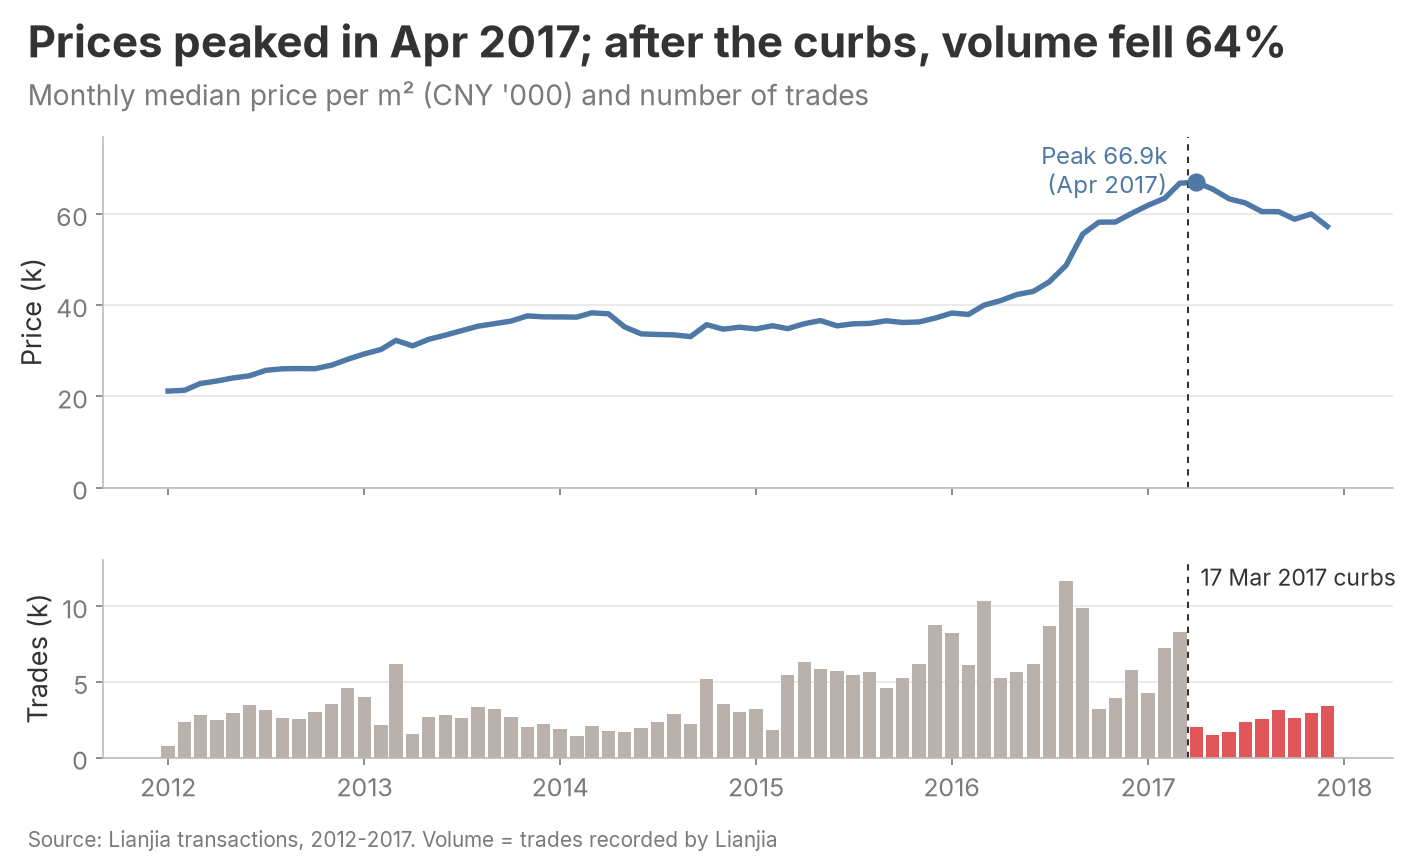

In [7]:
vol_drop = post.trades.mean() / pre.trades.mean() - 1
policy_lab = f"{POLICY.day} {POLICY:%b %Y}"
fig = plt.figure(figsize=bs.FIGSIZE, dpi=bs.DPI)
fig.text(0.04, 0.955, f"Prices peaked in {peak_month:%b %Y}; after the curbs, volume {'fell' if vol_drop < 0 else 'rose'} "
         f"{abs(vol_drop):.0%}", fontsize=21, fontweight="bold", va="top")
fig.text(0.04, 0.885, "Monthly median price per m² (CNY '000) and number of trades", fontsize=13.5, color=bs.MUTED, va="top")
ax1 = fig.add_axes([0.09, 0.43, 0.86, 0.39])
ax2 = fig.add_axes([0.09, 0.13, 0.86, 0.22], sharex=ax1)
ax1.plot(monthly.index, monthly.price / 1000, color=bs.HIGHLIGHT, lw=2.6)
ax1.scatter([peak_month], [monthly.price.max() / 1000], color=bs.HIGHLIGHT, s=60, zorder=3)
ax1.annotate(f"Peak {monthly.price.max()/1000:.1f}k\n({peak_month:%b %Y})", (peak_month, monthly.price.max() / 1000),
             xytext=(-14, 6), textcoords="offset points", ha="right", va="center", fontsize=11.5, color=bs.HIGHLIGHT)
ax1.set_ylabel("Price (k)")
ax1.set_ylim(0, monthly.price.max() / 1000 * 1.15)
bs.ygrid(ax1)
plt.setp(ax1.get_xticklabels(), visible=False)
ax2.bar(monthly.index, monthly.trades / 1000, width=25,
        color=[bs.NEGATIVE if d >= POLICY else bs.CONTEXT for d in monthly.index])
ax2.set_ylim(0, monthly.trades.max() / 1000 * 1.12)
ax2.set_ylabel("Trades (k)")
bs.ygrid(ax2)
for a in (ax1, ax2):
    a.axvline(POLICY, color=bs.INK, lw=1, ls=(0, (3, 3)))
ax2.text(POLICY, ax2.get_ylim()[1] * 0.98, f"  {policy_lab} curbs", fontsize=11, va="top", color=bs.INK)
publish(fig, "D1_boom_and_cooling.png", SRC + ". Volume = trades recorded by Lianjia")

**D2. How much of the growth came in the last two years?**

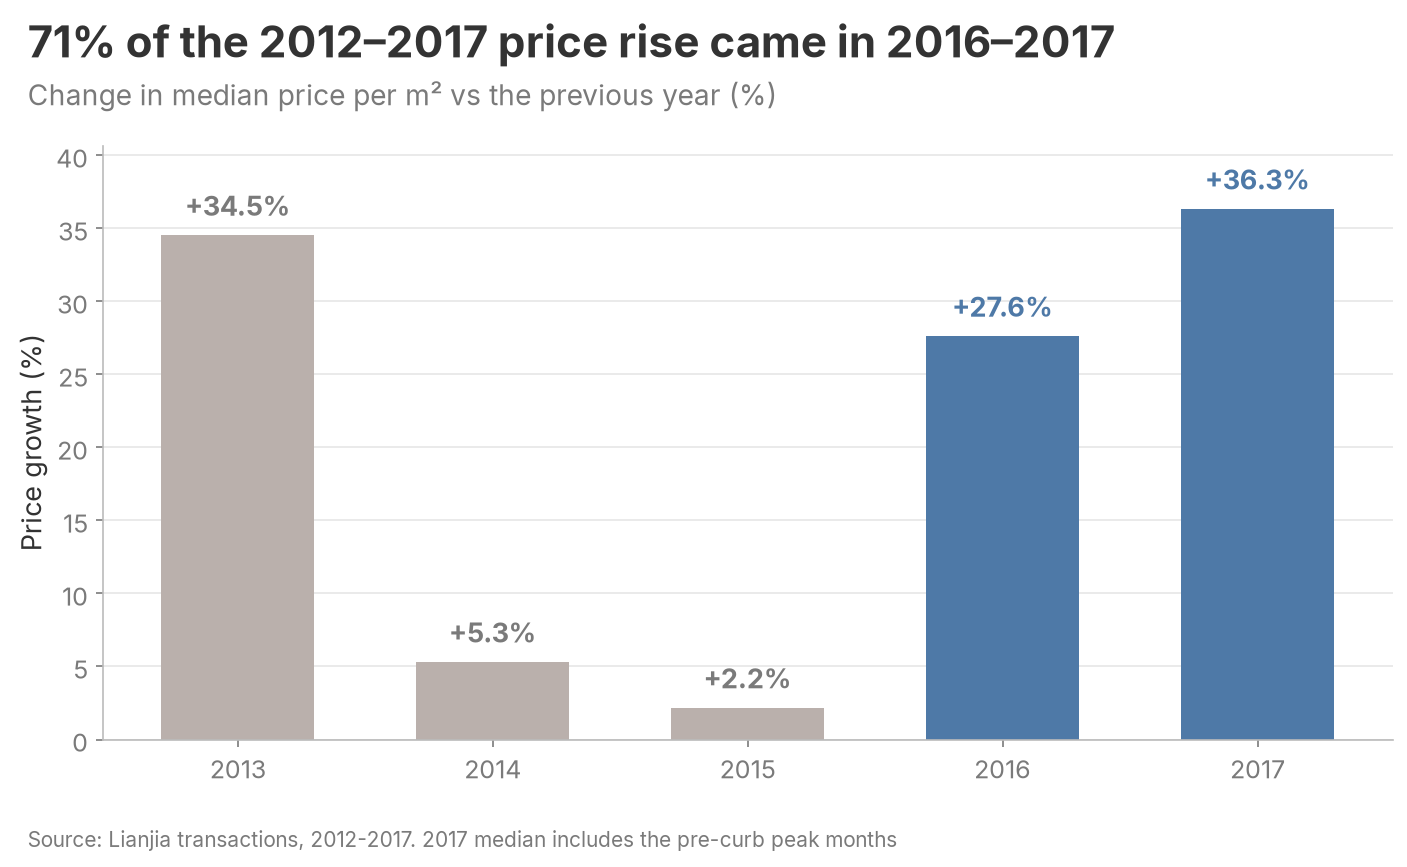

In [8]:
yoy = yearly.loc[YEARS].pct_change().dropna() * 100
share_last2 = (yearly[END] - yearly[END - 2]) / (yearly[END] - yearly[BASE])
fig, ax = bs.new_chart(f"{share_last2:.0%} of the {BASE}–{END} price rise came in {END - 1}–{END}",
                       "Change in median price per m² vs the previous year (%)")
cols = [bs.HIGHLIGHT if y >= END - 1 else bs.CONTEXT for y in yoy.index]
ax.bar(yoy.index.astype(str), yoy.values, color=cols, width=0.6)
lo, hi = padded(min(0, yoy.min()), yoy.max(), 0.12)
for i, v in enumerate(yoy.values):
    ax.text(i, v + (hi - lo) * 0.02 * (1 if v >= 0 else -1), f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top",
            fontsize=13, fontweight="bold", color=bs.HIGHLIGHT if cols[i] == bs.HIGHLIGHT else bs.MUTED)
ax.set_ylim(0 if yoy.min() >= 0 else lo, hi)
ax.set_ylabel("Price growth (%)")
bs.ygrid(ax)
publish(fig, "D2_growth_by_year.png", SRC + f". {END} median includes the pre-curb peak months")

**D3. Is the cooling deepening? (DOM and volume, from when DOM is recorded)**

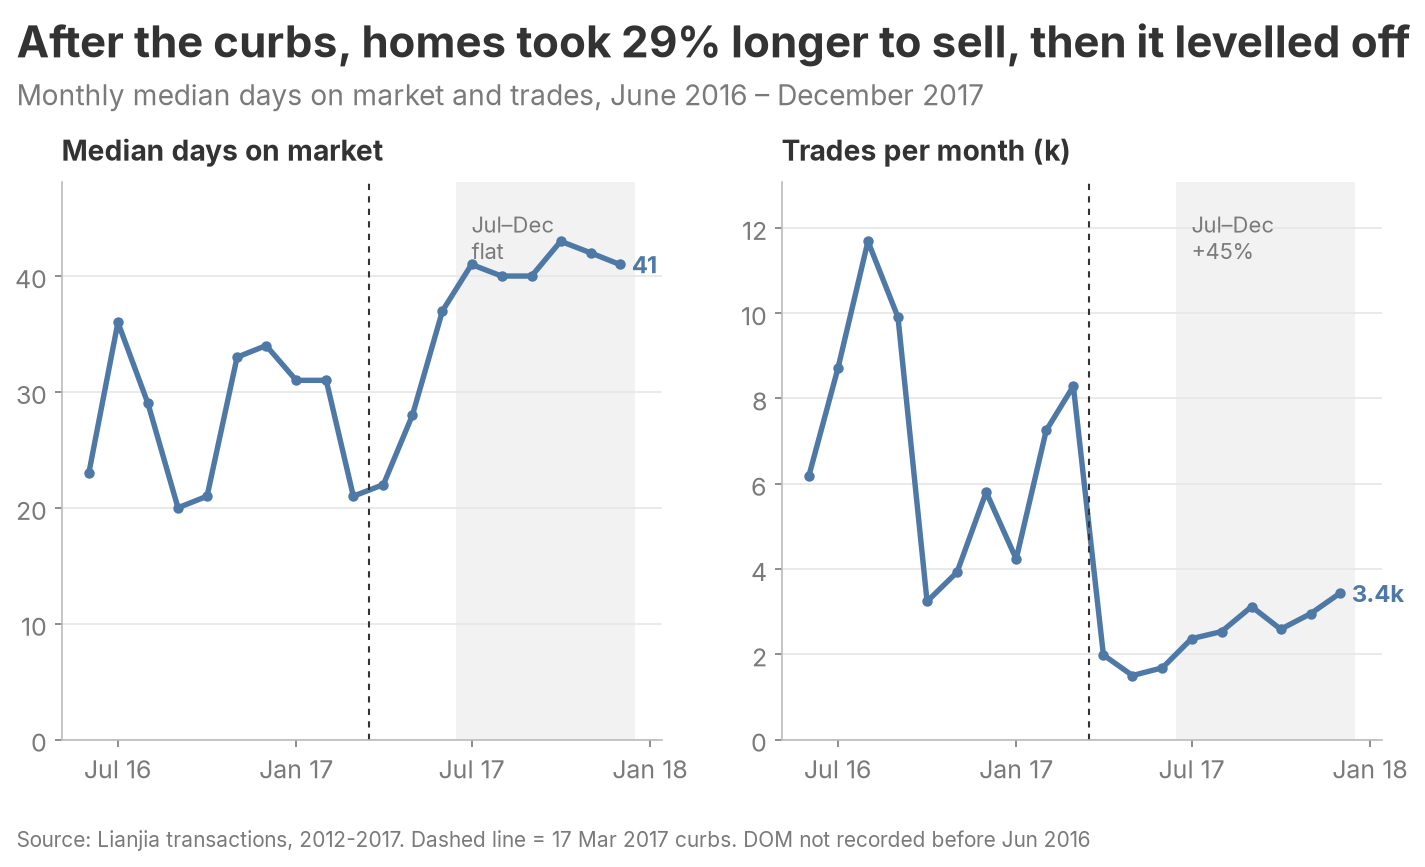

In [9]:
w = monthly.loc[str(DOM_START):f"{END}-12"]
tail = w.index[-6:]                       # the last six months
dom_up = post.dom.median() / pre.dom.median() - 1
tail_chg = w.dom.iloc[-1] / w.dom.loc[tail[0]] - 1
trend = "then it levelled off" if abs(tail_chg) < 0.1 else ("and kept rising" if tail_chg > 0 else "then eased")
fig = plt.figure(figsize=bs.FIGSIZE, dpi=bs.DPI)
fig.text(0.04, 0.955, f"After the curbs, homes took {dom_up:.0%} longer to sell, {trend}",
         fontsize=21, fontweight="bold", va="top")
fig.text(0.04, 0.885, f"Monthly median days on market and trades, {DOM_START_TS:%B %Y} – {w.index[-1]:%B %Y}",
         fontsize=13.5, color=bs.MUTED, va="top")
specs = [(w.dom, "Median days on market", lambda v: f"{v:.0f}"), (w.trades / 1000, "Trades per month (k)", lambda v: f"{v:.1f}k")]
for k, (s, lab, fmt) in enumerate(specs):
    ax = fig.add_axes([0.07 + k * 0.48, 0.15, 0.40, 0.62])
    ax.plot(s.index, s.values, color=bs.HIGHLIGHT, lw=2.6, marker="o", ms=4)
    ax.axvline(POLICY, color=bs.INK, lw=1, ls=(0, (3, 3)))
    ax.axvspan(tail[0] - pd.Timedelta(days=15), s.index.max() + pd.Timedelta(days=15), color="#F2F2F2", zorder=0)
    chg = s.iloc[-1] / s.loc[tail[0]] - 1
    ax.text(tail[0], s.max() * 1.06, f"{tail[0]:%b}–{tail[-1]:%b}\n" + ("flat" if abs(chg) < 0.1 else f"{chg:+.0%}"),
            fontsize=10.5, color=bs.MUTED, va="top")
    ax.set_title(lab, loc="left", fontsize=13.5, fontweight="bold", pad=10)
    ax.set_ylim(0, s.max() * 1.12)
    ax.text(s.index[-1], s.iloc[-1], "  " + fmt(s.iloc[-1]), va="center", fontsize=11.5, color=bs.HIGHLIGHT, fontweight="bold")
    ax.xaxis.set_major_locator(AutoDateLocator(minticks=3, maxticks=5))
    ax.xaxis.set_major_formatter(DateFormatter("%b %y"))
    bs.ygrid(ax)
publish(fig, "D3_cooling_dom_volume.png",
        SRC + f". Dashed line = {policy_lab} curbs. DOM not recorded before {DOM_START_TS:%b %Y}")

**D4. Which size and age segments attract the most followers per listing? (2017)**

size_lab   <50 m²  50–90 m²  90–140 m²  140+ m²
age_lab                                        
0–5 yrs       212      1496        852      181
6–15 yrs     1968      8059       6652     1630
16–30 yrs    2464     10682       2655      678
30+ yrs      1059      3272         46        2


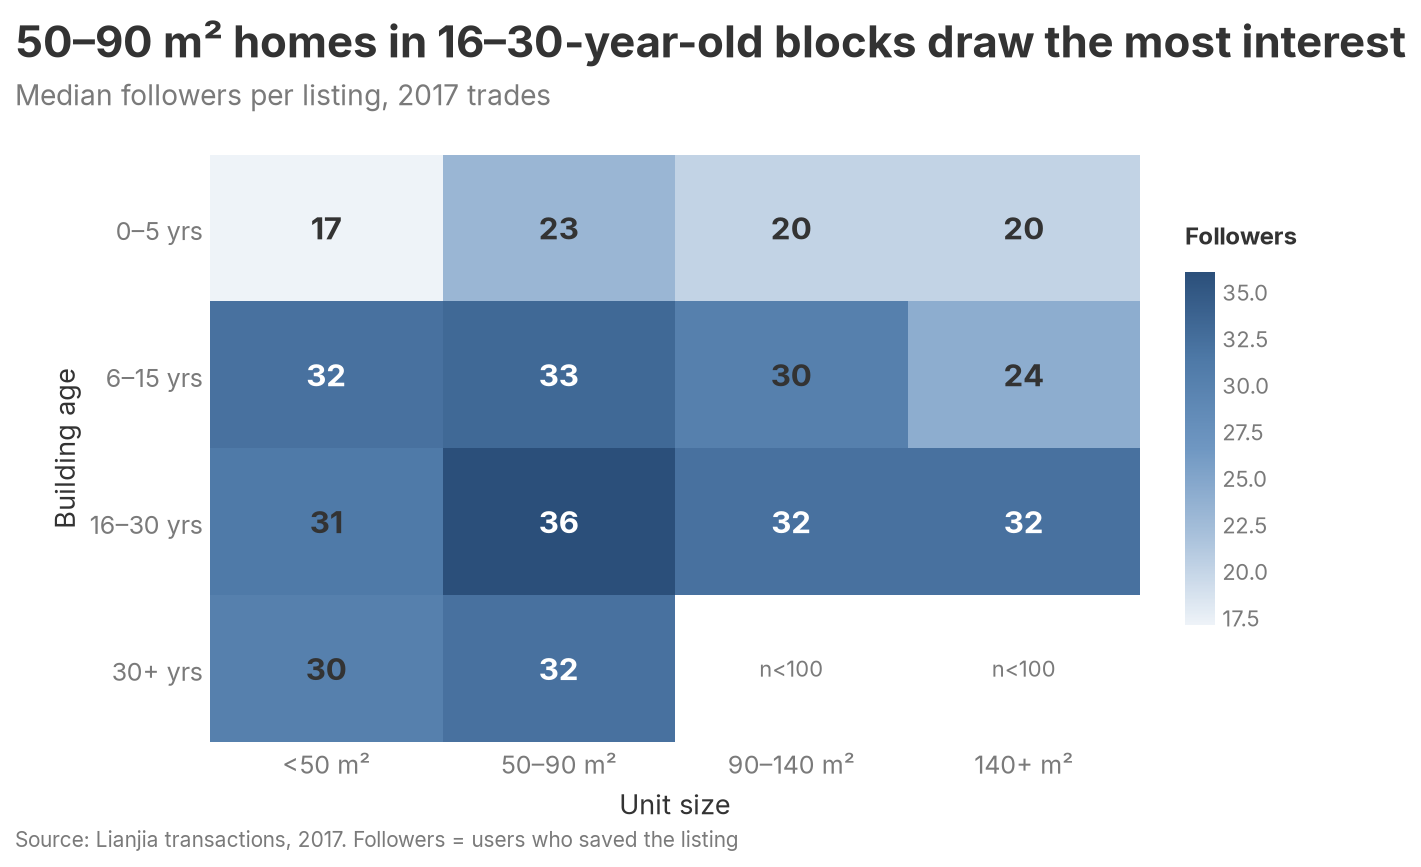

In [10]:
d17 = df[df.trade_year == END]
fol = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="median").loc[AGE_ORDER, SIZE_ORDER]
cnt = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="size").loc[AGE_ORDER, SIZE_ORDER]
fol = fol.where(cnt >= 100)
print(cnt)
best = fol.stack().idxmax()
fig, ax = bs.new_chart(f"{best[1]} homes in {best[0].replace(' yrs', '')}-year-old blocks draw the most interest",
                       f"Median followers per listing, {END} trades", rect=(0.17, 0.12, 0.62, 0.68))
cmap = LinearSegmentedColormap.from_list("b", ["#EEF3F8"] + bs.SEQ_BLUES[1:])
im = ax.imshow(fol.values, cmap=cmap, aspect="auto")
for i in range(fol.shape[0]):
    for j in range(fol.shape[1]):
        v = fol.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "n<100", ha="center", va="center", fontsize=10.5, color=bs.MUTED)
        else:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=15, fontweight="bold",
                    color="white" if v > np.nanpercentile(fol.values, 60) else bs.INK)
ax.set_xticks(range(len(SIZE_ORDER)), SIZE_ORDER)
ax.set_yticks(range(len(AGE_ORDER)), AGE_ORDER)
ax.set_xlabel("Unit size")
ax.set_ylabel("Building age")
ax.tick_params(length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cax = fig.add_axes([0.82, 0.25, 0.02, 0.42])
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10.5, length=0)
fig.text(0.82, 0.70, "Followers", fontsize=11.5, fontweight="bold")
publish(fig, "D4_followers_size_age.png", f"Lianjia transactions, {END}. Followers = users who saved the listing")

**D5. How does follower interest differ by characteristic? (2017)**

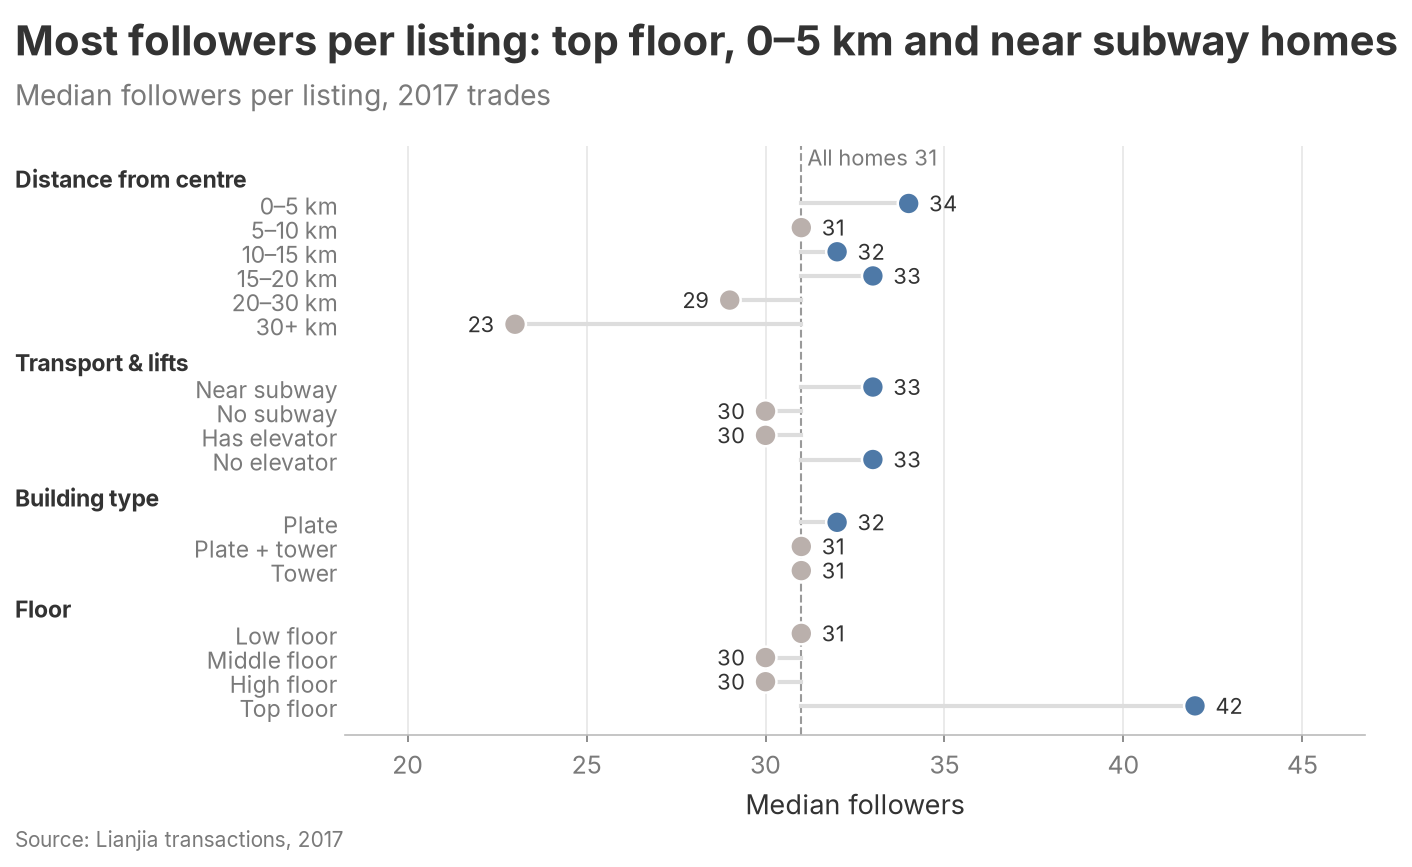

In [11]:
def grouped_dots(groups, values, title, subtitle, xlabel, name, ref=None, ref_label=None, fmt="{:.0f}",
                 src=SRC, colour_rule=None):
    """Horizontal dot plot with grouped categories. groups = [(header, [labels])], values = dict label->value."""
    rows, heads, y = [], [], 0
    for head, labs in groups:
        heads.append((y, head))
        y += 1
        for lab in labs:
            rows.append((y, lab, values[lab]))
            y += 1
        y += 0.6
    fig, ax = bs.new_chart(title, subtitle, rect=(0.26, 0.13, 0.68, 0.68))
    ys, labs, vals = zip(*rows)
    vals = np.array(vals)
    cols = [colour_rule(v) if colour_rule else bs.HIGHLIGHT for v in vals]
    if ref is not None:
        ax.axvline(ref, color="#9A9A9A", lw=1, ls="--", zorder=1)
        ax.text(ref, -0.9, f" {ref_label}", fontsize=10.5, color=bs.MUTED, va="center")
        for yy, v in zip(ys, vals):
            ax.plot([ref, v], [yy, yy], color="#DDDDDD", lw=2, zorder=1)
    ax.scatter(vals, ys, s=110, color=cols, zorder=3, edgecolor="white", lw=1.2)
    lo, hi = padded(vals.min(), vals.max(), 0.25, include=[ref] if ref is not None else [])
    span = hi - lo
    for yy, v, c in zip(ys, vals, cols):
        right = ref is None or v >= ref
        ax.text(v + (span * 0.02 if right else -span * 0.02), yy, fmt.format(v), va="center",
                ha="left" if right else "right", fontsize=10.5, color=bs.INK)
    ax.set_yticks(ys, labs)
    tr = blended_transform_factory(fig.transFigure, ax.transData)
    for yh, head in heads:
        ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
    ax.tick_params(axis="y", length=0, labelsize=11)
    ax.spines["left"].set_visible(False)
    ax.set_ylim(y - 0.4, -1.4)
    ax.set_xlim(lo, hi)
    ax.set_xlabel(xlabel)
    bs.xgrid(ax)
    publish(fig, name, src)


GROUPS_CHAR = [("Distance from centre", BANDS),
               ("Transport & lifts", ["Near subway", "No subway", "Has elevator", "No elevator"]),
               ("Building type", BTYPES),
               ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]
vals = {}
for col in ["band", "subway_lab", "elev_lab", "btype", "floor_lab"]:
    vals.update(d17.groupby(col, observed=True).followers.median().to_dict())
med17 = d17.followers.median()
group_best = sorted(((vals[max(labs, key=vals.get)], max(labs, key=vals.get)) for _, labs in GROUPS_CHAR), reverse=True)
top = [phrase(lab) for v, lab in group_best[:3] if v > med17]
grouped_dots(GROUPS_CHAR, vals, f"Most followers per listing: {join_names(top)} homes" if top else
             "No characteristic lifts followers above the typical home",
             f"Median followers per listing, {END} trades", "Median followers", "D5_followers_by_characteristic.png",
             ref=med17, ref_label=f"All homes {med17:.0f}",
             colour_rule=lambda v: bs.HIGHLIGHT if v > med17 else bs.CONTEXT,
             src=f"Lianjia transactions, {END}")

**D6. Has new-home demand kept cooling? (yearbook table 3-20)**

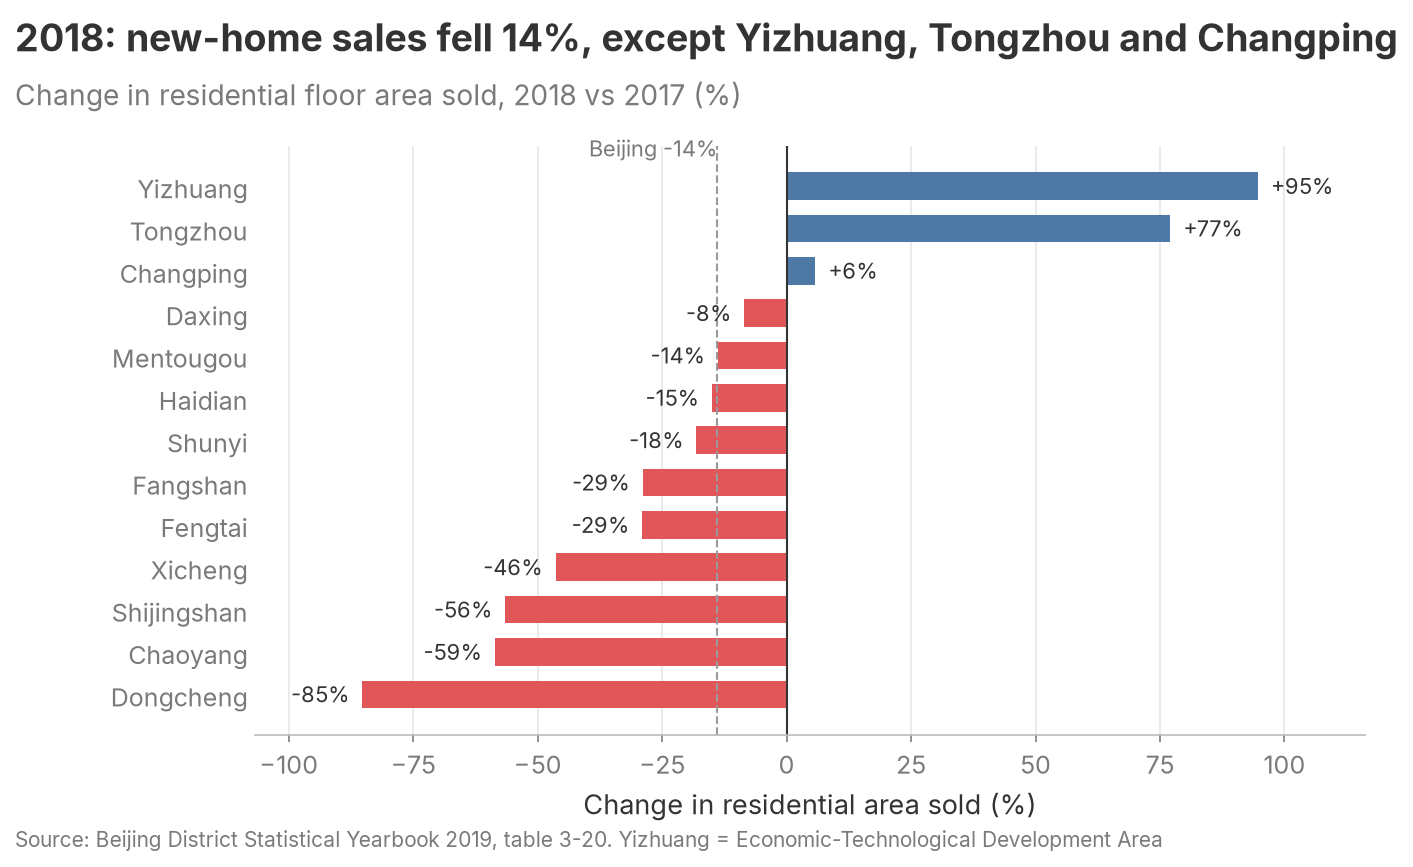

In [12]:
col = next(c for c in supply.columns if c.startswith("#住宅销售面积") and "增长速度" in c)
y1 = max(int(c.rsplit("|", 1)[1]) for c in supply.columns if c.startswith("#住宅销售面积") and c.rsplit("|", 1)[1].strip().isdigit())
res = supply[col]
city = res["Beijing"]
res = res[res.index.isin(LIANJIA)].sort_values()          # districts that appear in the Lianjia data
risers = list(res[res > 0].index[::-1])
tail_txt = f", except {join_names(risers)}" if city < 0 and risers else ""
fig, ax = bs.new_chart(f"{y1}: new-home sales {'fell' if city < 0 else 'rose'} {abs(city):.0f}%{tail_txt}",
                       f"Change in residential floor area sold, {y1} vs {y1 - 1} (%)", rect=(0.2, 0.13, 0.74, 0.68))
cols = [bs.HIGHLIGHT if v > 0 else bs.NEGATIVE for v in res.values]
ax.barh(res.index, res.values, color=cols, height=0.65)
lo, hi = padded(min(0, res.min()), max(0, res.max()), 0.12)
for i, v in enumerate(res.values):
    ax.text(v + (hi - lo) * 0.012 * (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=10.5)
ax.axvline(0, color=bs.INK, lw=1)
ax.axvline(city, color="#9A9A9A", lw=1, ls="--")
ax.text(city, len(res) - 0.3, f"Beijing {city:+.0f}%", ha="right", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(lo, hi)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Change in residential area sold (%)")
bs.xgrid(ax)
publish(fig, "D6_new_home_sales.png",
        "Beijing District Statistical Yearbook 2019, table 3-20. Yizhuang = Economic-Technological Development Area")

## P1. Property characteristics to target

               fam           lab     x    y     col
Distance to centre        0–5 km  56.9 23.7 #4E79A7
Distance to centre       5–10 km  21.1 20.5 #4E79A7
Distance to centre      10–15 km   0.2 20.1 #4E79A7
Distance to centre      15–20 km -17.0 21.9 #4E79A7
Distance to centre      20–30 km -28.4 23.0 #4E79A7
Distance to centre        30+ km -33.1 25.8 #4E79A7
            Subway   Near subway  11.0 20.5 #F28E2B
            Subway     No subway -14.6 20.7 #F28E2B
     Building type         Plate  -4.1 21.2 #9C755F
     Building type Plate + tower   0.8 19.4 #9C755F
     Building type         Tower   6.6 20.2 #9C755F


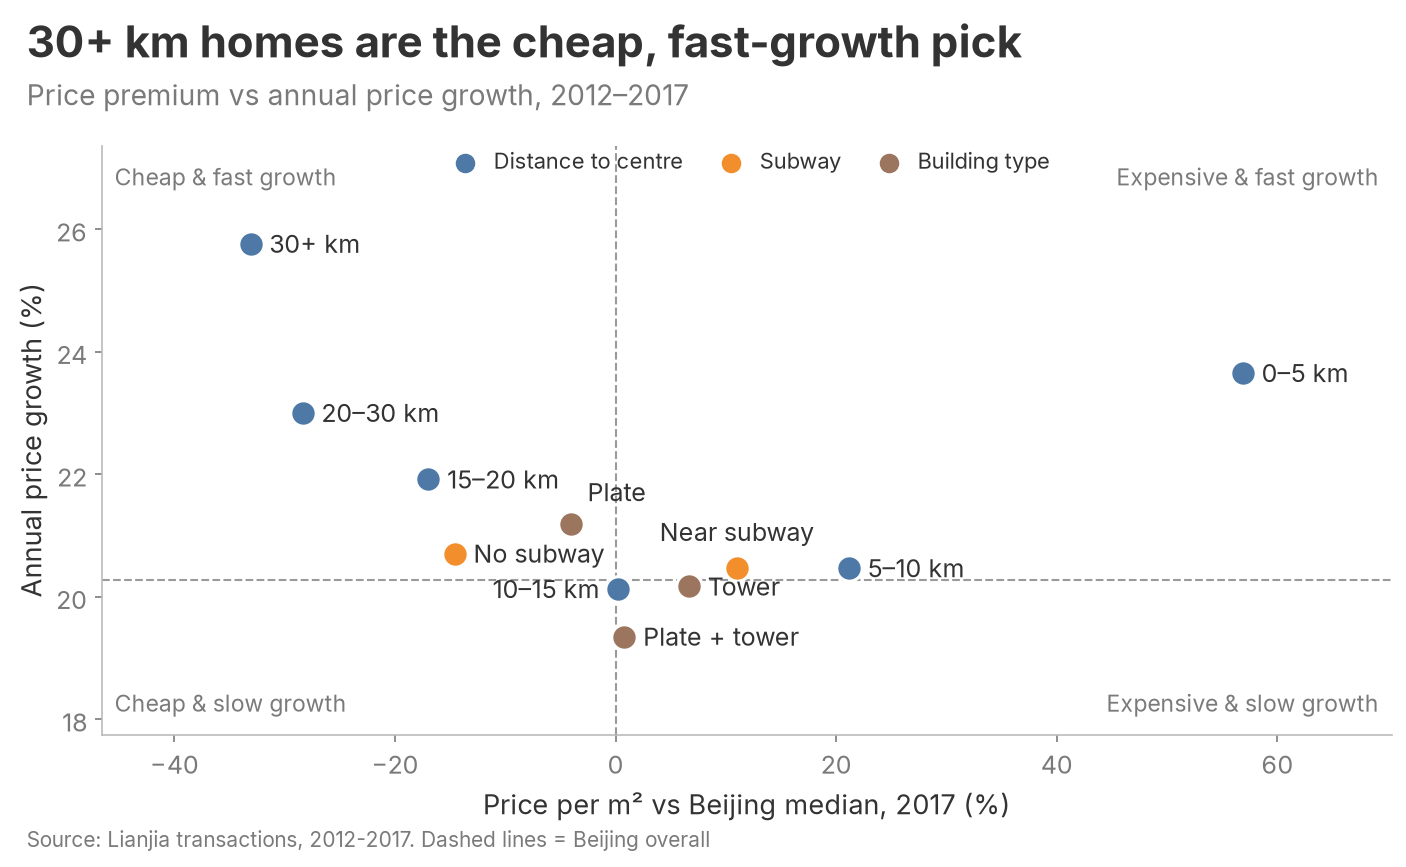

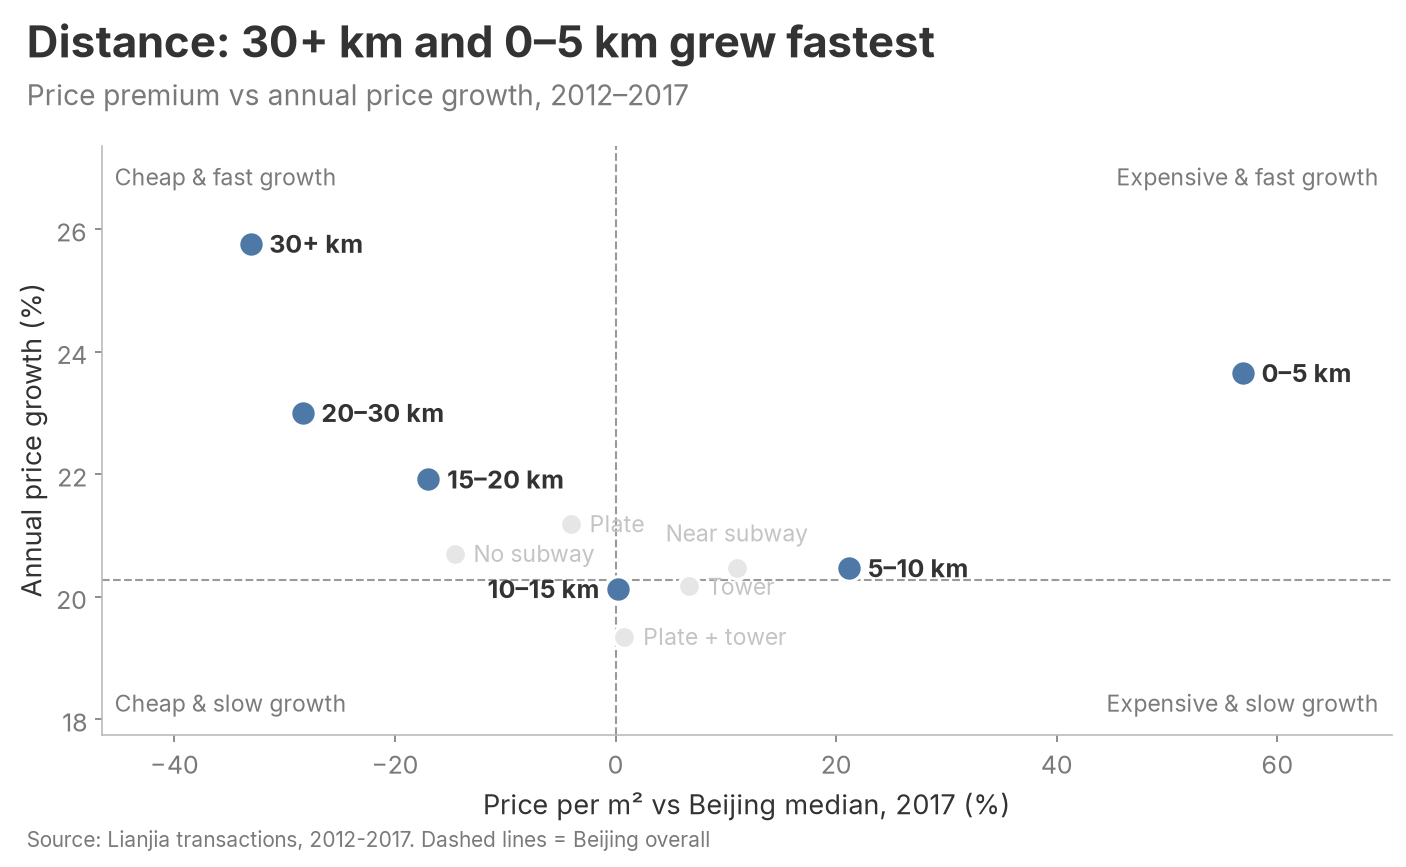

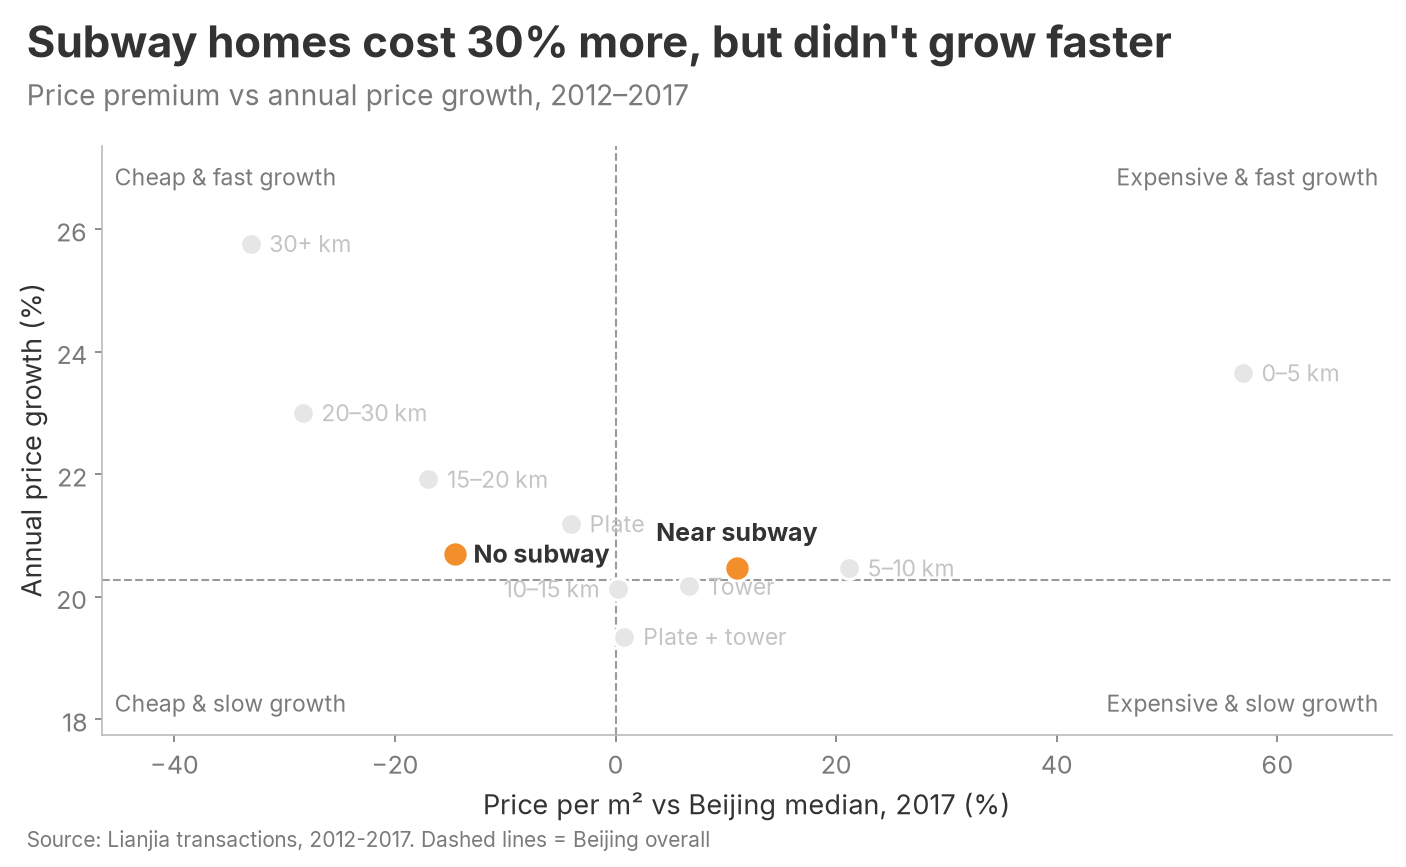

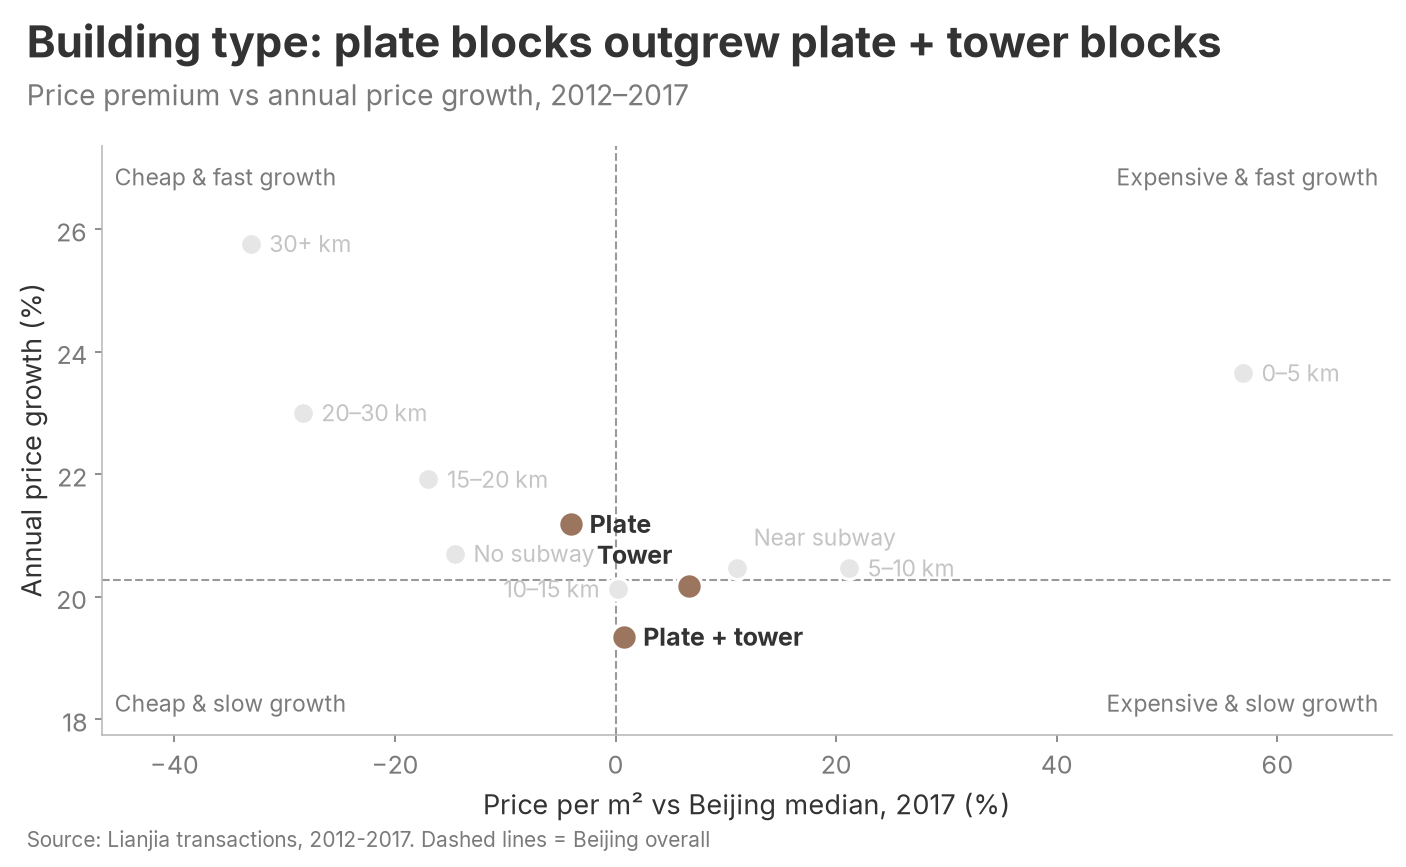

In [13]:
def growth_table(col, data=None):
    data = df if data is None else data
    t = data.groupby([col, "trade_year"], observed=True).price.median().unstack()
    out = pd.DataFrame({"p0": t[BASE], "p1": t[END]})
    out["cagr"] = (out.p1 / out.p0) ** (1 / N_YRS) - 1
    out["n"] = data.groupby(col, observed=True).size()
    return out


overall_p1 = yearly[END]
dist, subway, btype = growth_table("band"), growth_table("subway_lab"), growth_table("btype")
FAMILIES = {"Distance to centre": (dist, bs.HIGHLIGHT), "Subway": (subway, bs.HIGHLIGHT_2), "Building type": (btype, "#9C755F")}
P = pd.DataFrame([dict(fam=fam, lab=lab, x=(r.p1 / overall_p1 - 1) * 100, y=r.cagr * 100, col=col)
                  for fam, (tab, col) in FAMILIES.items() for lab, r in tab.iterrows()])

# Titles from the numbers
sub_prem = (subway.p1["Near subway"] / subway.p1["No subway"] - 1) * 100
sub_gdiff = (subway.cagr["Near subway"] - subway.cagr["No subway"]) * 100
if abs(sub_gdiff) < 0.5:
    SUBWAY_VERDICT = f"Subway homes cost {sub_prem:.0f}% more, but didn't grow faster"
else:
    SUBWAY_VERDICT = f"Subway homes cost {sub_prem:.0f}% more and grew {abs(sub_gdiff):.1f} pp a year {'faster' if sub_gdiff > 0 else 'slower'}"
cheap_fast = P[(P.x < 0) & (P.y > overall_cagr * 100)].sort_values("y", ascending=False)
b_best, b_worst = btype.cagr.idxmax(), btype.cagr.idxmin()
d_top = list(dist.cagr.nlargest(2).index)
SPOT_TITLES = {
    None: (f"{cheap_fast.lab.iloc[0]} homes are the cheap, fast-growth pick" if len(cheap_fast)
           else "No group is both cheaper and faster-growing than Beijing"),
    "Distance to centre": f"Distance: {join_names(d_top)} grew fastest",
    "Subway": SUBWAY_VERDICT,
    "Building type": f"Building type: {phrase(b_best)} blocks outgrew {phrase(b_worst)} blocks",
}
print(P.round(1).to_string(index=False))


def quadrant(spot, fname):
    fig, ax = bs.new_chart(SPOT_TITLES[spot], f"Price premium vs annual price growth, {BASE}–{END}")
    ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--", zorder=1)
    ax.axvline(0, color="#9A9A9A", lw=1, ls="--", zorder=1)
    ax.set_xlim(*padded(P.x.min(), P.x.max(), 0.15, include=[0]))
    ax.set_ylim(*padded(P.y.min(), P.y.max(), 0.25, include=[overall_cagr * 100]))
    q = dict(transform=ax.transAxes, fontsize=11, color=bs.MUTED)
    ax.text(0.01, 0.97, "Cheap & fast growth", ha="left", va="top", **q)
    ax.text(0.99, 0.97, "Expensive & fast growth", ha="right", va="top", **q)
    ax.text(0.01, 0.03, "Cheap & slow growth", ha="left", va="bottom", **q)
    ax.text(0.99, 0.03, "Expensive & slow growth", ha="right", va="bottom", **q)
    if spot is None:
        for fam, (_, col) in FAMILIES.items():
            ax.scatter([], [], color=col, s=70, label=fam)
        ax.legend(loc="upper center", ncol=3, fontsize=10.5, handletextpad=0.3, columnspacing=1.2, bbox_to_anchor=(0.5, 1.03))
    on = (P.fam == spot) if spot else pd.Series(True, index=P.index)
    for (_, p), o in zip(P.iterrows(), on):
        ax.scatter(p.x, p.y, s=150 if o else 110, color=p.col if o else bs.FADE,   # group keeps its own colour
                   edgecolor="white", lw=1.5, zorder=3 if o else 2)
    order = list(P.index[on]) + list(P.index[~on])                                  # spotlit labels get first pick
    place_labels(ax, P.x[order], P.y[order], P.lab[order],
                 styles=[dict(color=bs.INK if on[i] else bs.FADE_TEXT, fontsize=12 if on[i] else 11,
                              fontweight="bold" if (on[i] and spot) else "normal") for i in order])
    ax.set_xlabel(f"Price per m² vs Beijing median, {END} (%)")
    ax.set_ylabel("Annual price growth (%)")
    publish(fig, fname, SRC + ". Dashed lines = Beijing overall")


quadrant(None, "P1_premium_vs_growth.png")
quadrant("Distance to centre", "P1a_premium_vs_growth_distance.png")
quadrant("Subway", "P1b_premium_vs_growth_subway.png")
quadrant("Building type", "P1c_premium_vs_growth_building_type.png")

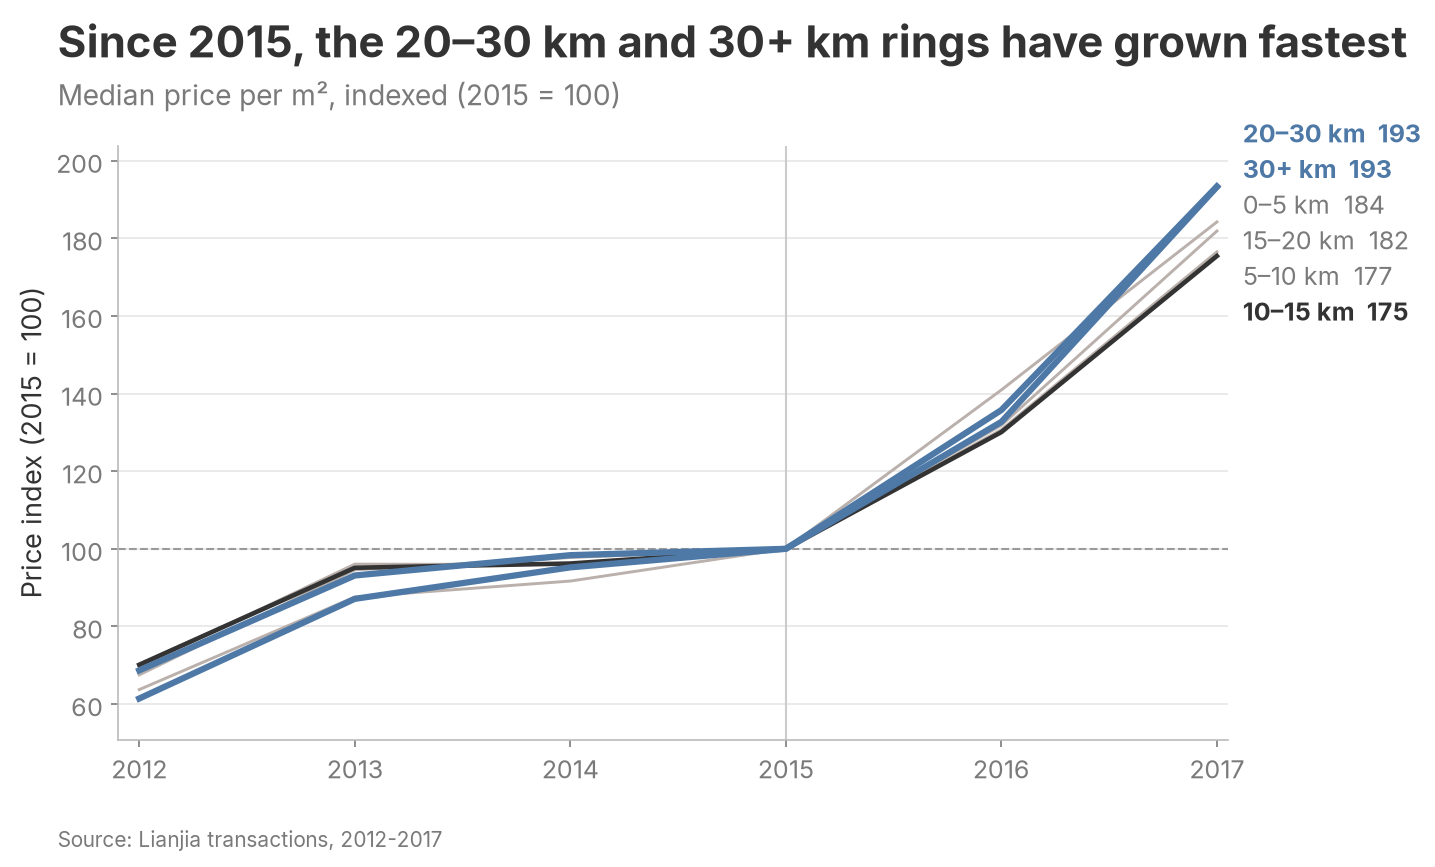

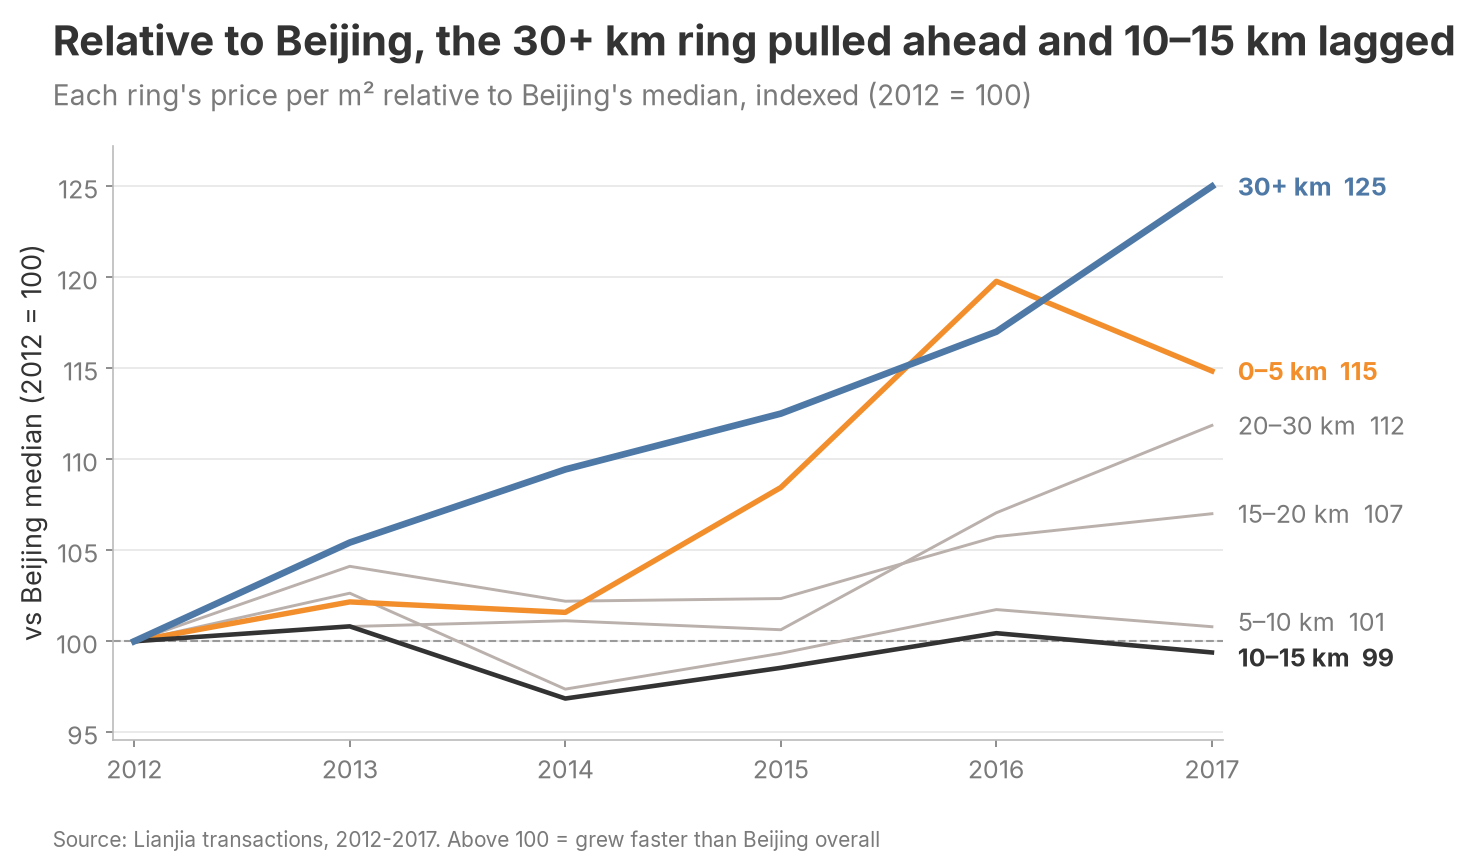

In [14]:
t_band = df.groupby(["band", "trade_year"], observed=True).price.median().unstack()[YEARS]


def index_chart(idx, title, subtitle, ylabel, styles, ref_line=None):
    fig, ax = bs.new_chart(title, subtitle, rect=(0.08, 0.15, 0.74, 0.66))
    if ref_line is not None:
        ax.axhline(ref_line, color="#9A9A9A", lw=1, ls="--", zorder=1)
    for b in idx.index:
        c, w_ = styles.get(b, (bs.CONTEXT, 1.4))
        ax.plot(YEARS, idx.loc[b], color=c, lw=w_, zorder=3 if b in styles else 2)
    lo, hi = padded(np.nanmin(idx.values), np.nanmax(idx.values), 0.08, include=[ref_line] if ref_line is not None else [])
    ax.set_ylim(lo, hi)
    ends = idx[END].values
    for b, y_end, y_lab in zip(idx.index, ends, bs.spread_labels(list(ends), min_gap=(hi - lo) * 0.06)):
        c, _ = styles.get(b, (bs.MUTED, 0))
        ax.text(END + 0.12, y_lab, f"{b}  {y_end:.0f}", va="center", fontsize=12, color=c,
                fontweight="bold" if b in styles else "normal")
    ax.set_xticks(YEARS)
    ax.set_xlim(BASE - 0.1, END + 0.05)
    ax.set_ylabel(ylabel)
    bs.ygrid(ax)
    return fig, ax


idx15 = t_band.div(t_band[INDEX_BASE], axis=0) * 100
top2, slow = list(idx15[END].nlargest(2).index), idx15[END].idxmin()
fig, ax = index_chart(idx15, f"Since {INDEX_BASE}, the {join_names(top2)} rings have grown fastest",
                      f"Median price per m², indexed ({INDEX_BASE} = 100)", f"Price index ({INDEX_BASE} = 100)",
                      styles={**{b: (bs.HIGHLIGHT, 3) for b in top2}, slow: (bs.INK, 2.2)}, ref_line=100)
ax.axvline(INDEX_BASE, color="#CCCCCC", lw=1, zorder=1)
publish(fig, "P2a_indexed_growth_base2015.png", SRC)

rel = t_band.div(yearly[YEARS], axis=1)
rel = rel.div(rel[BASE], axis=0) * 100
r_top, r_2nd, r_low = rel[END].nlargest(2).index[0], rel[END].nlargest(2).index[1], rel[END].idxmin()
fig, ax = index_chart(rel, f"Relative to Beijing, the {r_top} ring pulled ahead and {r_low} lagged",
                      f"Each ring's price per m² relative to Beijing's median, indexed ({BASE} = 100)",
                      f"vs Beijing median ({BASE} = 100)",
                      styles={r_top: (bs.HIGHLIGHT, 3.2), r_2nd: (bs.HIGHLIGHT_2, 2.6), r_low: (bs.INK, 2.2)}, ref_line=100)
publish(fig, "P2b_growth_vs_beijing_by_distance.png", SRC + ". Above 100 = grew faster than Beijing overall")

top-quintile cells by district: {'Tongzhou': 14, 'Xicheng': 7, 'Shunyi': 5, 'Daxing': 3, 'Changping': 3, 'Haidian': 2, 'Fengtai': 1, 'Dongcheng': 1, 'Chaoyang': 1}


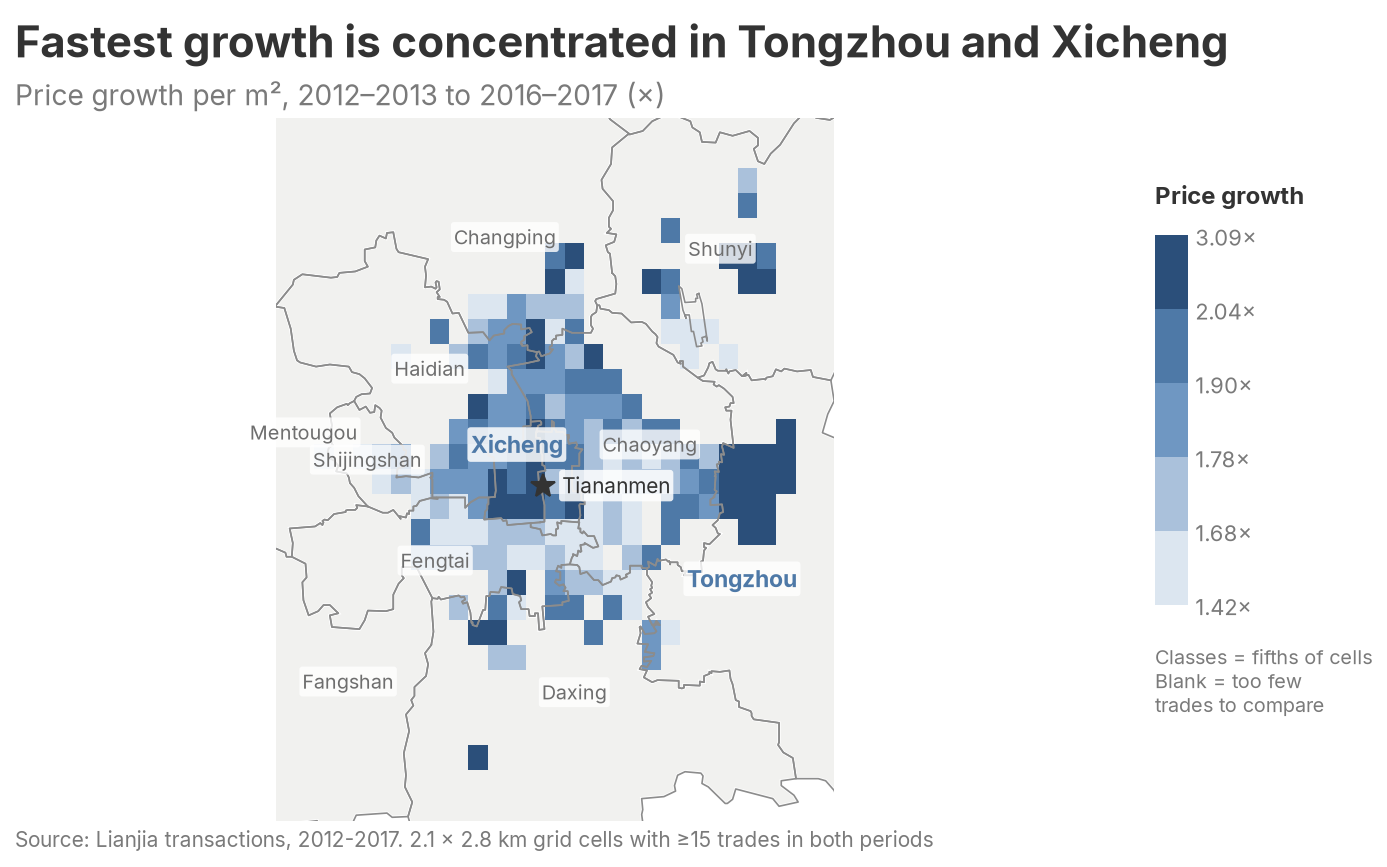

In [15]:
# P3 growth map on district basemap
cell = 0.025
MIN_CELL = 15
m_ = df.copy()
m_["gx"] = np.floor(m_.Lng / cell) * cell
m_["gy"] = np.floor(m_.Lat / cell) * cell
m_["period"] = np.where(m_.trade_year <= BASE + 1, "early", np.where(m_.trade_year >= END - 1, "late", None))
g = m_.dropna(subset=["period"]).groupby(["gx", "gy", "period"]).price.agg(["median", "size"]).unstack()
g = g[(g[("size", "early")] >= MIN_CELL) & (g[("size", "late")] >= MIN_CELL)]
g["growth"] = g[("median", "late")] / g[("median", "early")]
g = g.reset_index()
g.columns = ["_".join(c).strip("_") if isinstance(c, tuple) else c for c in g.columns]

# View = the coloured cells plus a margin; colour classes = growth quintiles
XLIM = (g.gx.min() - 2 * cell, g.gx.max() + 3 * cell)
YLIM = (g.gy.min() - 2 * cell, g.gy.max() + 3 * cell)
bounds = np.quantile(g.growth, np.linspace(0, 1, 6)).round(2)
bounds[0], bounds[-1] = np.floor(g.growth.min() * 100) / 100, np.ceil(g.growth.max() * 100) / 100
bounds = np.unique(bounds)

# Which districts hold the top-quintile cells
cell_hit = tree.query([Point(x + cell / 2, y + cell / 2) for x, y in zip(g.gx, g.gy)], predicate="within")
g["district"] = "outside"
g.loc[g.index[cell_hit[0]], "district"] = [names[i] for i in cell_hit[1]]
hot_cells = g[g.growth >= bounds[-2]]
hot = list(hot_cells.district[hot_cells.district != "outside"].value_counts().index[:2])
print("top-quintile cells by district:", hot_cells.district.value_counts().to_dict())

# District labels at a point inside each district's visible area. Small districts are only labelled when they
# are one of the fastest-growing ones, and those labels (plus Tiananmen) are placed clear of the others.
view = box(XLIM[0], YLIM[0], XLIM[1], YLIM[1])
labels, small_hot = {}, []
for nm, geom in polys.items():
    part = geom.intersection(view)
    if nm not in LIANJIA or part.is_empty:
        continue
    p = part.representative_point()
    if part.area > 0.015 * view.area:
        labels[nm] = (p.x, p.y, nm in hot)
    elif nm in hot:
        small_hot.append((nm, p.x, p.y))


def basemap(ax, labels):
    for geom in polys.values():
        for gg in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
            x, y = gg.exterior.xy
            ax.fill(x, y, facecolor="#F1F1EF", edgecolor="white", lw=1.6, zorder=1)
    for nm, (x, y, h) in labels.items():
        ax.text(x, y, nm, fontsize=11 if h else 9.5, ha="center", va="center", zorder=6,
                color=bs.HIGHLIGHT if h else "#6E6E6E", fontweight="bold" if h else "normal",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))


def outlines(ax):
    for geom in polys.values():
        for gg in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
            x, y = gg.exterior.xy
            ax.plot(x, y, color="#8C8C8C", lw=0.8, zorder=3)


fig, ax = bs.new_chart(f"Fastest growth is concentrated in {join_names(hot)}",
                       f"Price growth per m², {BASE}–{BASE+1} to {END-1}–{END} (×)", rect=(0.02, 0.06, 0.76, 0.79))
basemap(ax, labels)
cmap = LinearSegmentedColormap.from_list("blues", bs.SEQ_BLUES)
xs_ = np.round(np.arange(XLIM[0] - cell, XLIM[1] + cell, cell) / cell) * cell
ys_ = np.round(np.arange(YLIM[0] - cell, YLIM[1] + cell, cell) / cell) * cell
Z = np.full((len(ys_), len(xs_)), np.nan)
xi = np.round((g.gx - xs_[0]) / cell).astype(int)
yi = np.round((g.gy - ys_[0]) / cell).astype(int)
ok = (xi >= 0) & (xi < len(xs_)) & (yi >= 0) & (yi < len(ys_))
Z[yi[ok], xi[ok]] = g.growth[ok]
mesh = ax.pcolormesh(np.append(xs_, xs_[-1] + cell), np.append(ys_, ys_[-1] + cell), Z, cmap=cmap,
                     norm=BoundaryNorm(bounds, cmap.N), edgecolors="none", zorder=2)
outlines(ax)
ax.plot(*CENTRE, marker="*", color=bs.INK, ms=12, zorder=6)
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
ax.set_aspect(1 / np.cos(np.radians(CENTRE[1])))
ax.axis("off")
white = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
extra = [("Tiananmen", *CENTRE, dict(fontsize=10, color=bs.INK, bbox=white))] + \
        [(nm, x, y, dict(fontsize=11, color=bs.HIGHLIGHT, fontweight="bold", bbox=white)) for nm, x, y in small_hot]
place_labels(ax, [e[1] for e in extra], [e[2] for e in extra], [e[0] for e in extra], styles=[e[3] for e in extra], size=60)
cax = fig.add_axes([0.8, 0.3, 0.022, 0.42])
cb = fig.colorbar(mesh, cax=cax, ticks=bounds)
cb.ax.set_yticklabels([f"{b:.2f}×" for b in bounds])
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10.5, length=0)
fig.text(0.8, 0.745, "Price growth", fontsize=11.5, fontweight="bold")
fig.text(0.8, 0.255, "Classes = fifths of cells\nBlank = too few\ntrades to compare", fontsize=9.5, color=bs.MUTED, va="top")
km_y, km_x = cell * 110.57, cell * 111.32 * np.cos(np.radians(CENTRE[1]))
publish(fig, "P3_growth_map.png", SRC + f". {km_x:.1f} × {km_y:.1f} km grid cells with ≥{MIN_CELL} trades in both periods")

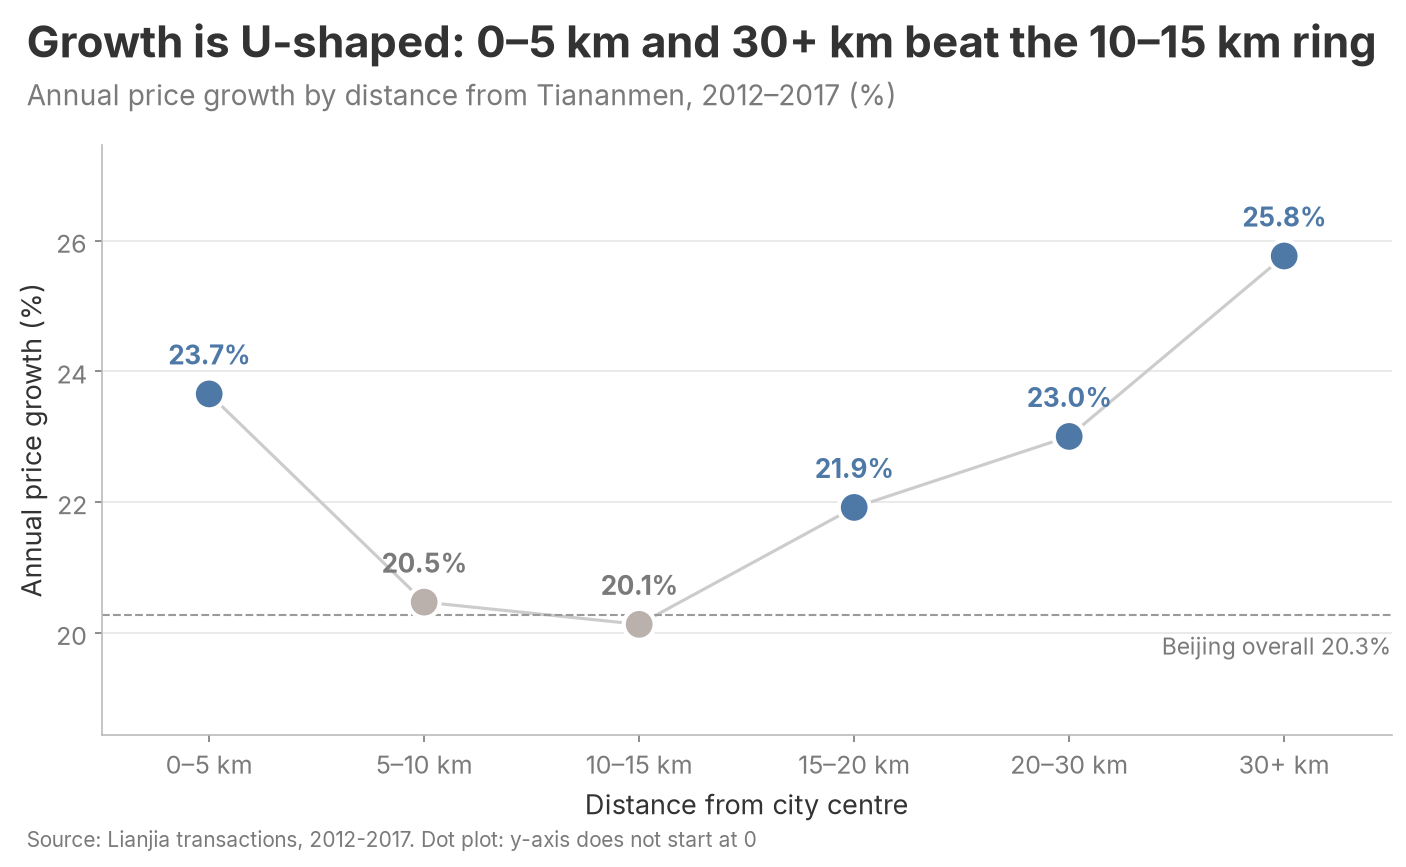

In [16]:
# P4 growth by distance, dot plot
y = dist.cagr.reindex(BANDS).values * 100
imin = int(np.argmin(y))
if 0 < imin < len(y) - 1:
    p4_title = f"Growth is U-shaped: {BANDS[0]} and {BANDS[-1]} beat the {BANDS[imin]} ring"
else:
    p4_title = f"Growth is fastest in the {BANDS[int(np.argmax(y))]} ring"
fig, ax = bs.new_chart(p4_title, f"Annual price growth by distance from Tiananmen, {BASE}–{END} (%)")
cols = [bs.HIGHLIGHT if v > overall_cagr * 100 + 1 else bs.CONTEXT for v in y]
ax.plot(range(len(y)), y, color="#CCCCCC", lw=1.5, zorder=1)
ax.scatter(range(len(y)), y, s=220, color=cols, edgecolor="white", lw=2, zorder=3)
lo, hi = padded(y.min(), y.max(), 0.3, include=[overall_cagr * 100])
for i, v in enumerate(y):
    ax.text(i, v + (hi - lo) * 0.05, f"{v:.1f}%", ha="center", fontsize=12.5, fontweight="bold",
            color=bs.HIGHLIGHT if cols[i] == bs.HIGHLIGHT else bs.MUTED)
ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.text(len(y) - 0.5, overall_cagr * 100 - (hi - lo) * 0.03, f"Beijing overall {overall_cagr*100:.1f}%", ha="right", va="top",
        fontsize=11, color=bs.MUTED)
ax.set_xticks(range(len(y)), BANDS)
ax.set_xlim(-0.5, len(y) - 0.5)
ax.set_ylim(lo, hi)
ax.set_ylabel("Annual price growth (%)")
ax.set_xlabel("Distance from city centre")
bs.ygrid(ax)
publish(fig, "P4_growth_by_distance_dotplot.png", SRC + ". Dot plot: y-axis does not start at 0")

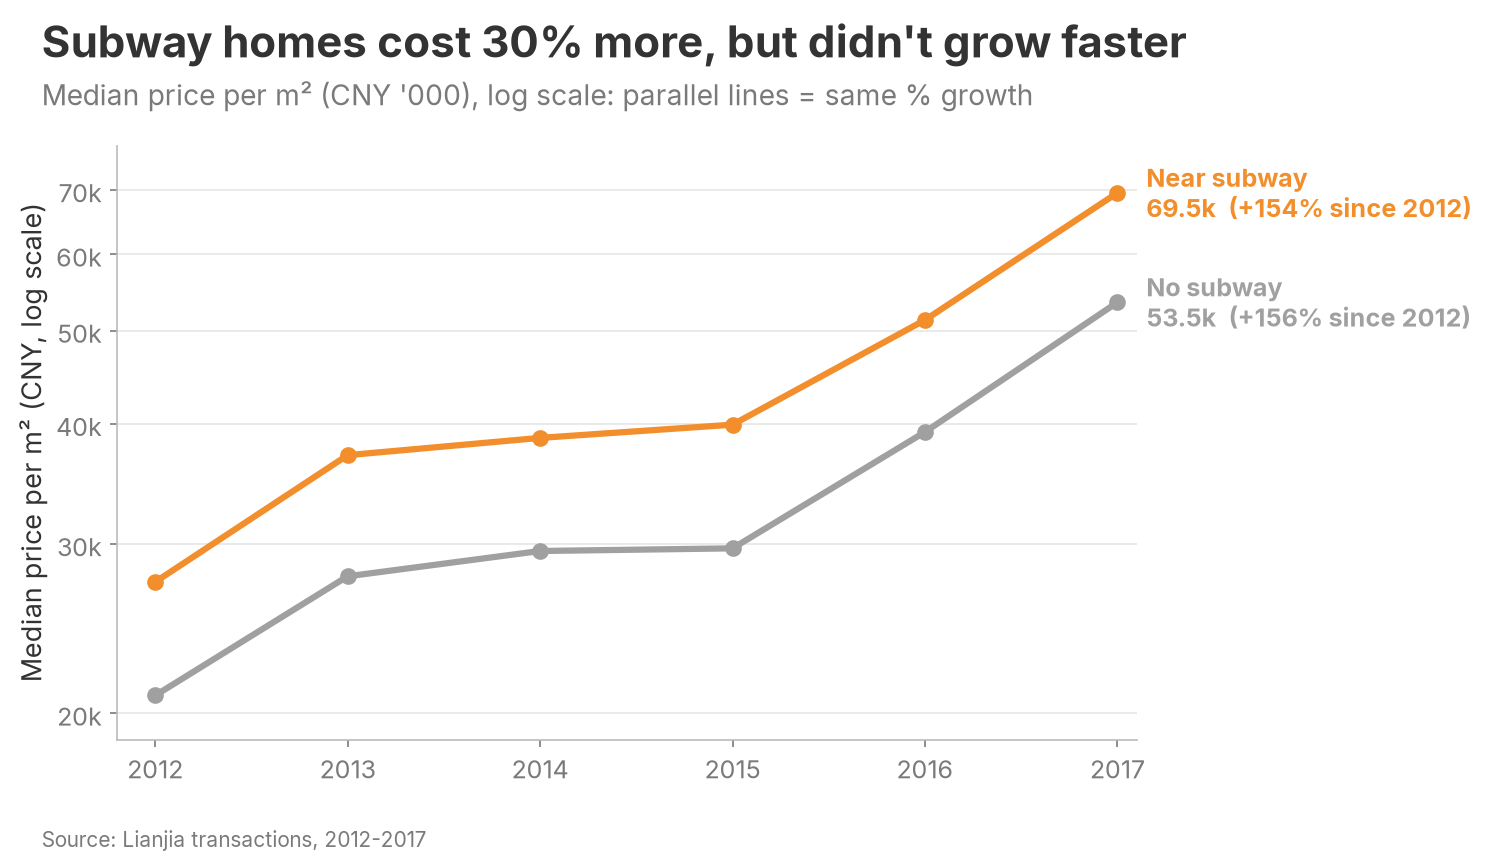

In [17]:
# P5 subway over time (log scale)
ts = df.groupby(["subway_lab", "trade_year"]).price.median().unstack()[YEARS] / 1000
lo, hi = ts.values.min() * 0.9, ts.values.max() * 1.12
ticks = [t for t in range(int(np.floor(lo / 10) * 10), int(np.ceil(hi / 10) * 10) + 1, 10) if lo <= t <= hi]
fig, ax = bs.new_chart(SUBWAY_VERDICT, "Median price per m² (CNY '000), log scale: parallel lines = same % growth",
                       rect=(0.09, 0.15, 0.68, 0.66))
lines = [("Near subway", bs.HIGHLIGHT_2), ("No subway", "#A0A0A0")]
ends = np.log([ts.loc[lab, END] for lab, _ in lines])
lab_y = np.exp(bs.spread_labels(list(ends), min_gap=(np.log(hi) - np.log(lo)) * 0.14))
for (lab, c), yl in zip(lines, lab_y):
    s = ts.loc[lab]
    ax.plot(YEARS, s.values, color=c, lw=3, marker="o", ms=7, zorder=3)
    ax.text(END + 0.15, yl, f"{lab}\n{s[END]:.1f}k  (+{(s[END]/s[BASE]-1)*100:.0f}% since {BASE})",
            va="center", fontsize=12, color=c, fontweight="bold")
ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(NullLocator())
ax.set_yticklabels([f"{v}k" for v in ticks])
ax.set_ylim(lo, hi)
ax.set_xticks(YEARS)
ax.set_xlim(BASE - 0.2, END + 0.1)
ax.set_ylabel("Median price per m² (CNY, log scale)")
bs.ygrid(ax)
publish(fig, "P5_subway_over_time.png", SRC)

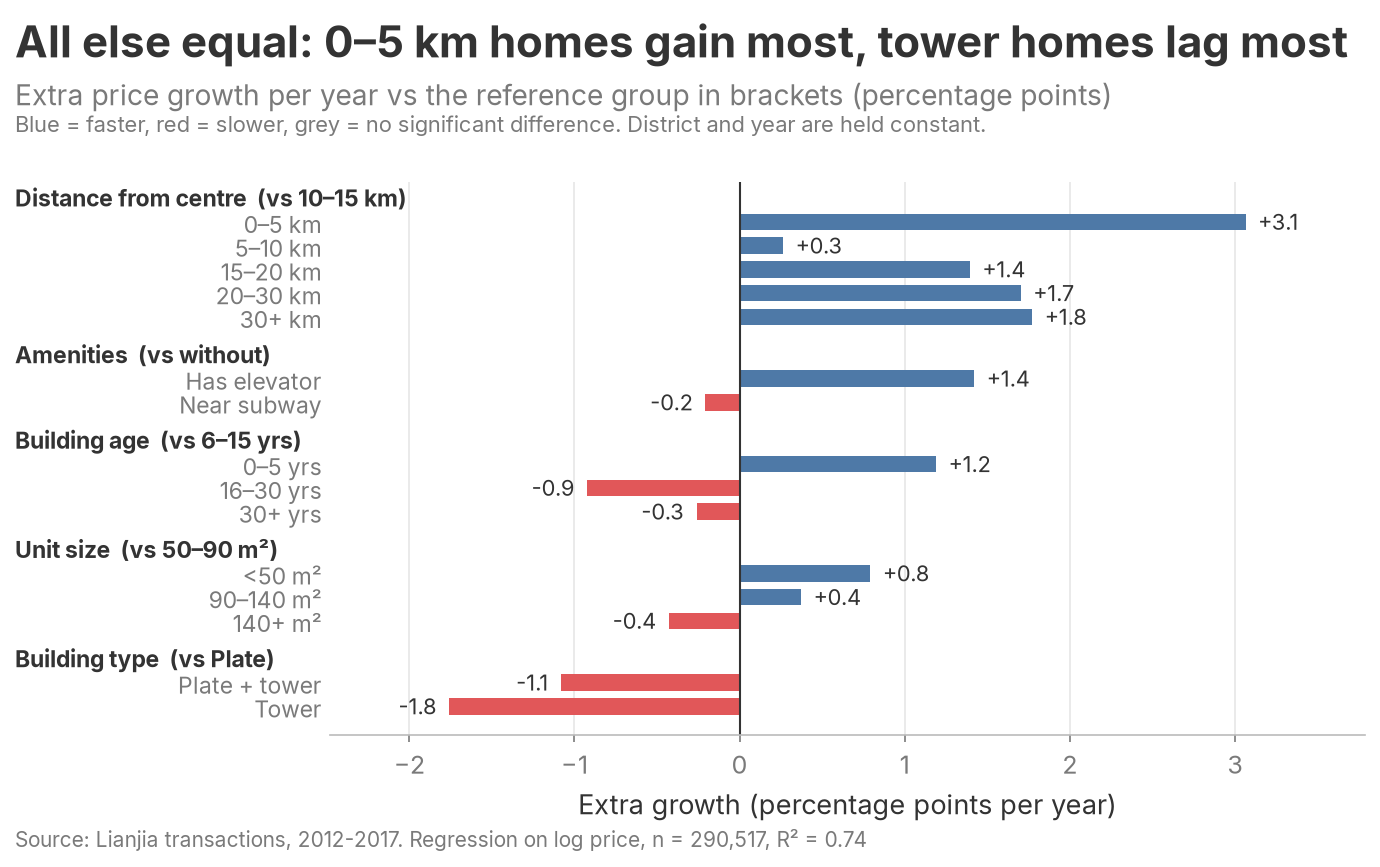

In [18]:
# P6 growth drivers regression: log(price) = year FE + district FE + traits + trait x (years since 2012)
# The trait x time coefficient = extra annual growth vs the reference group, other traits/district/year held constant.
m = df.dropna(subset=["band", "btype", "size_category", "age_bucket"]).copy()
m["t"] = m.trade_year - BASE
REF = {"band": "10–15 km", "btype": "Plate", "size_category": "50-90", "age_bucket": "6-15"}
ORDER = {"band": BANDS, "btype": BTYPES, "size_category": list(SIZE_MAP), "age_bucket": list(AGE_MAP)}
NICE = {"band": "Distance from centre", "btype": "Building type", "size_category": "Unit size", "age_bucket": "Building age"}
LAB = {"band": str, "btype": str, "size_category": SIZE_MAP.get, "age_bucket": AGE_MAP.get}
feat = pd.DataFrame({"subway": m.subway, "elevator": m.elevator}, index=m.index).astype(float)
for col, ref in REF.items():
    dm = pd.get_dummies(m[col].astype(str), prefix=col, prefix_sep="=", dtype=float).drop(columns=f"{col}={ref}")
    feat = pd.concat([feat, dm], axis=1)
fe_ = pd.concat([pd.get_dummies(m.trade_year, prefix="yr", drop_first=True, dtype=float),
                 pd.get_dummies(m.district, prefix="dist", drop_first=True, dtype=float)], axis=1)
X = pd.concat([pd.Series(1.0, index=m.index, name="const"), fe_, feat, feat.mul(m.t.values, axis=0).add_suffix(" x t")], axis=1)
Xv, yv = X.values, np.log(m.price.values)
beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
resid = yv - Xv @ beta
XtX_inv = np.linalg.inv(Xv.T @ Xv)
V = XtX_inv @ ((Xv * resid[:, None] ** 2).T @ Xv) @ XtX_inv * len(yv) / (len(yv) - Xv.shape[1])   # HC1 robust
coef = pd.DataFrame({"beta": beta, "se": np.sqrt(np.diag(V))}, index=X.columns)
r2 = 1 - resid.var() / yv.var()


def trait_group(col):
    items = [(f"{col}={v}", LAB[col](v)) for v in ORDER[col] if v != REF[col] and f"{col}={v} x t" in coef.index]
    return (f"{NICE[col]}  (vs {LAB[col](REF[col])})", items)


GROUPS = [trait_group("band"), ("Amenities  (vs without)", [("elevator", "Has elevator"), ("subway", "Near subway")]),
          trait_group("age_bucket"), trait_group("size_category"), trait_group("btype")]
rows, heads, yc = [], [], 0
for head, items in GROUPS:
    heads.append((yc, head)); yc += 1
    for key, lab in items:
        b, se = coef.loc[f"{key} x t"]
        rows.append(dict(lab=lab, pp=(np.exp(b) - 1) * 100, sig=abs(b / se) > 1.96, y=yc)); yc += 1
    yc += 0.6
R = pd.DataFrame(rows)
NOUN = {"Has elevator": "homes with lifts", "Near subway": "homes near the subway"}
sig_ = R[R.sig]
b_, w_ = sig_.loc[sig_.pp.idxmax()], sig_.loc[sig_.pp.idxmin()]
fig, ax = bs.new_chart(f"All else equal: {NOUN.get(b_.lab, phrase(b_.lab) + ' homes')} gain most, "
                       f"{NOUN.get(w_.lab, phrase(w_.lab) + ' homes')} lag most",
                       "Extra price growth per year vs the reference group in brackets (percentage points)",
                       rect=(0.25, 0.15, 0.69, 0.62))
cols = [bs.CONTEXT if not s else (bs.HIGHLIGHT if v > 0 else bs.NEGATIVE) for v, s in zip(R.pp, R.sig)]
ax.barh(R.y, R.pp, color=cols, height=0.7)
lo, hi = padded(min(0, R.pp.min()), max(0, R.pp.max()), 0.15)
for _, r in R.iterrows():
    ax.text(r.pp + (hi - lo) * 0.012 * (1 if r.pp >= 0 else -1), r.y, f"{r.pp:+.1f}", va="center",
            ha="left" if r.pp >= 0 else "right", fontsize=10.5, color=bs.INK if r.sig else bs.MUTED)
ax.set_yticks(R.y, R.lab)
tr = blended_transform_factory(fig.transFigure, ax.transData)
for yh, head in heads:
    ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
ax.tick_params(axis="y", labelsize=11, length=0, pad=4)
ax.axvline(0, color=bs.INK, lw=1)
ax.set_ylim(yc - 0.4, -0.7)
ax.set_xlim(lo, hi)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Extra growth (percentage points per year)")
bs.xgrid(ax)
fig.text(0.04, 0.825, "Blue = faster, red = slower, grey = no significant difference. District and year are held constant.",
         fontsize=10.5, color=bs.MUTED)
publish(fig, "P6_growth_drivers.png", f"{SRC}. Regression on log price, n = {len(m):,}, R² = {r2:.2f}")

## P2. Which districts show the strongest and most consistent appreciation?
Districts with fewer than `MIN_DISTRICT_TRADES` trades in 2012 or 2017 are excluded from growth rankings
(a thin base year makes CAGR meaningless). The excluded list is printed below.

In [19]:
dist_year = df.groupby(["dname", "trade_year"]).price.median().unstack()[YEARS]
dist_n = df.groupby(["dname", "trade_year"]).size().unstack()[YEARS]
print(dist_n)
valid = dist_n[[BASE, END]].min(axis=1) >= MIN_DISTRICT_TRADES
EXCLUDED = list(valid[~valid].index)
dcagr = ((dist_year[END] / dist_year[BASE]) ** (1 / N_YRS) - 1)[valid].sort_values() * 100
print(f"excluded (<{MIN_DISTRICT_TRADES} trades in {BASE} or {END}):", EXCLUDED)
EXCL_TXT = f"{join_names(EXCLUDED)} excluded (too few trades in {BASE} or {END})" if EXCLUDED else "No districts excluded"

trade_year    2012   2013  2014   2015   2016   2017
dname                                               
Changping     3647   4094  3142   7095  11553   5508
Chaoyang     11509  11834  9899  21953  29684  14244
Daxing        1732   1927  1281   2772   4170   2160
Dongcheng     1676   1650  1661   3995   4352   2195
Fangshan         1      2     1    437   1448    730
Fengtai       3400   3334  2637   5564   7968   3918
Haidian       4410   4039  4193   7913   9398   4673
Mentougou      122    142   107    280    464    259
Shijingshan   1371   1360  1220   2000   2831   1356
Shunyi        1292   1371   918   1805   2170   1089
Tongzhou      1543   2198  1230   2817   2440   1652
Xicheng       3435   3235  3517   7051   7615   3776
Yizhuang       138    259   148    373    922    348
excluded (<100 trades in 2012 or 2017): ['Fangshan']


**PD1. Highest growth in median price per m²**

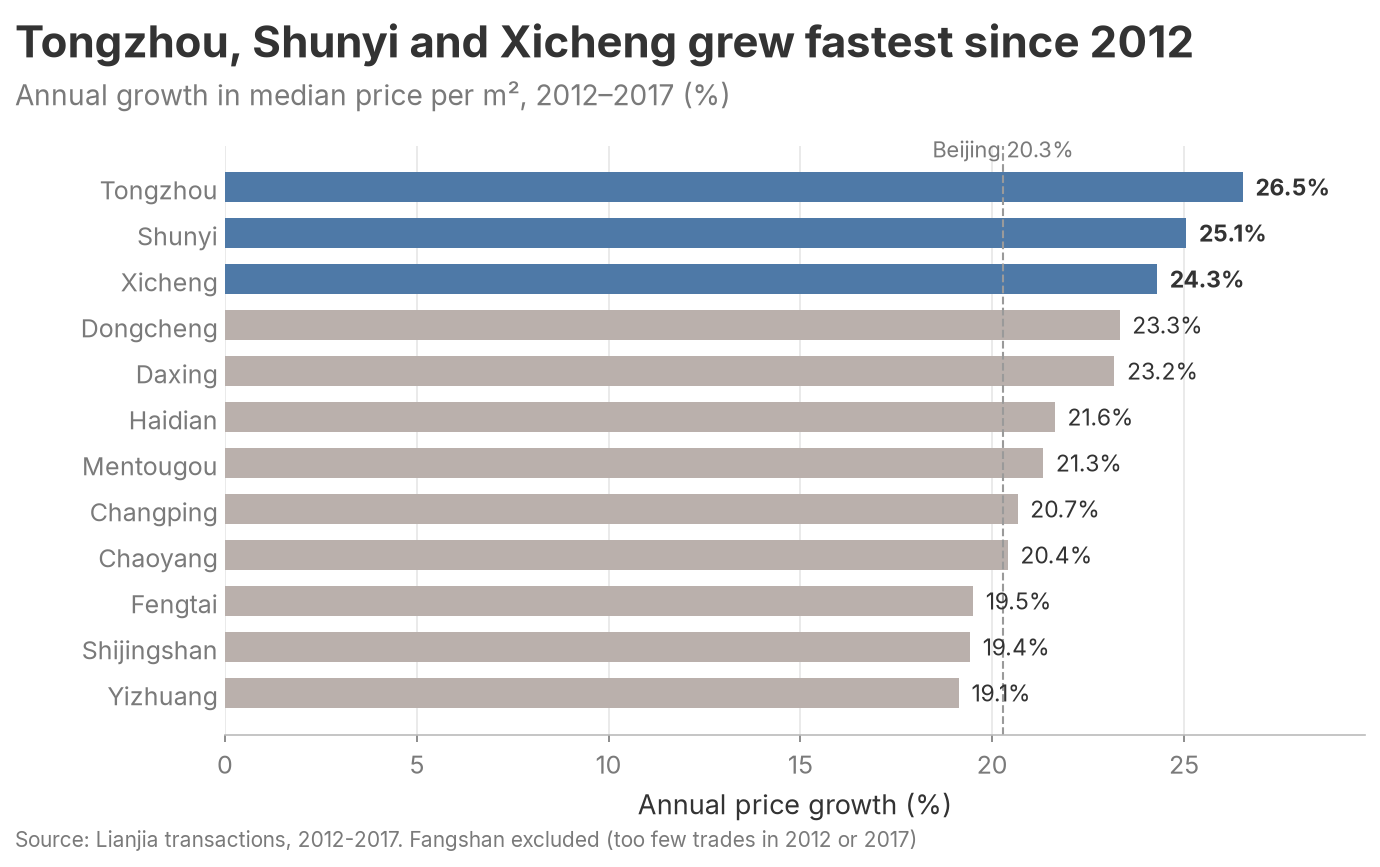

In [20]:
top3 = list(dcagr.index[-3:][::-1])
fig, ax = bs.new_chart(f"{join_names(top3)} grew fastest since {BASE}",
                       f"Annual growth in median price per m², {BASE}–{END} (%)", rect=(0.18, 0.13, 0.76, 0.68))
cols = [bs.HIGHLIGHT if d in top3 else bs.CONTEXT for d in dcagr.index]
ax.barh(dcagr.index, dcagr.values, color=cols, height=0.65)
lo, hi = padded(min(0, dcagr.min()), dcagr.max(), 0.12)
for i, v in enumerate(dcagr.values):
    ax.text(v + (hi - lo) * 0.01, i, f"{v:.1f}%", va="center", fontsize=11, color=bs.INK,
            fontweight="bold" if cols[i] == bs.HIGHLIGHT else "normal")
ax.axvline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.text(overall_cagr * 100, len(dcagr) - 0.35, f"Beijing {overall_cagr*100:.1f}%", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(0 if dcagr.min() >= 0 else lo, hi)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Annual price growth (%)")
bs.xgrid(ax)
publish(fig, "PD1_district_growth.png", SRC + ". " + EXCL_TXT)

**PD2. Was growth consistent or concentrated in a few years?**

burst years: [2013, 2016, 2017] | share of each district's gains in them: {'Tongzhou': 0.9, 'Shunyi': 0.93, 'Xicheng': 0.88, 'Dongcheng': 0.93, 'Daxing': 0.95, 'Haidian': 0.94, 'Mentougou': 0.95, 'Changping': 1.0, 'Chaoyang': 0.96, 'Fengtai': 1.0, 'Shijingshan': 0.99, 'Yizhuang': 0.91}


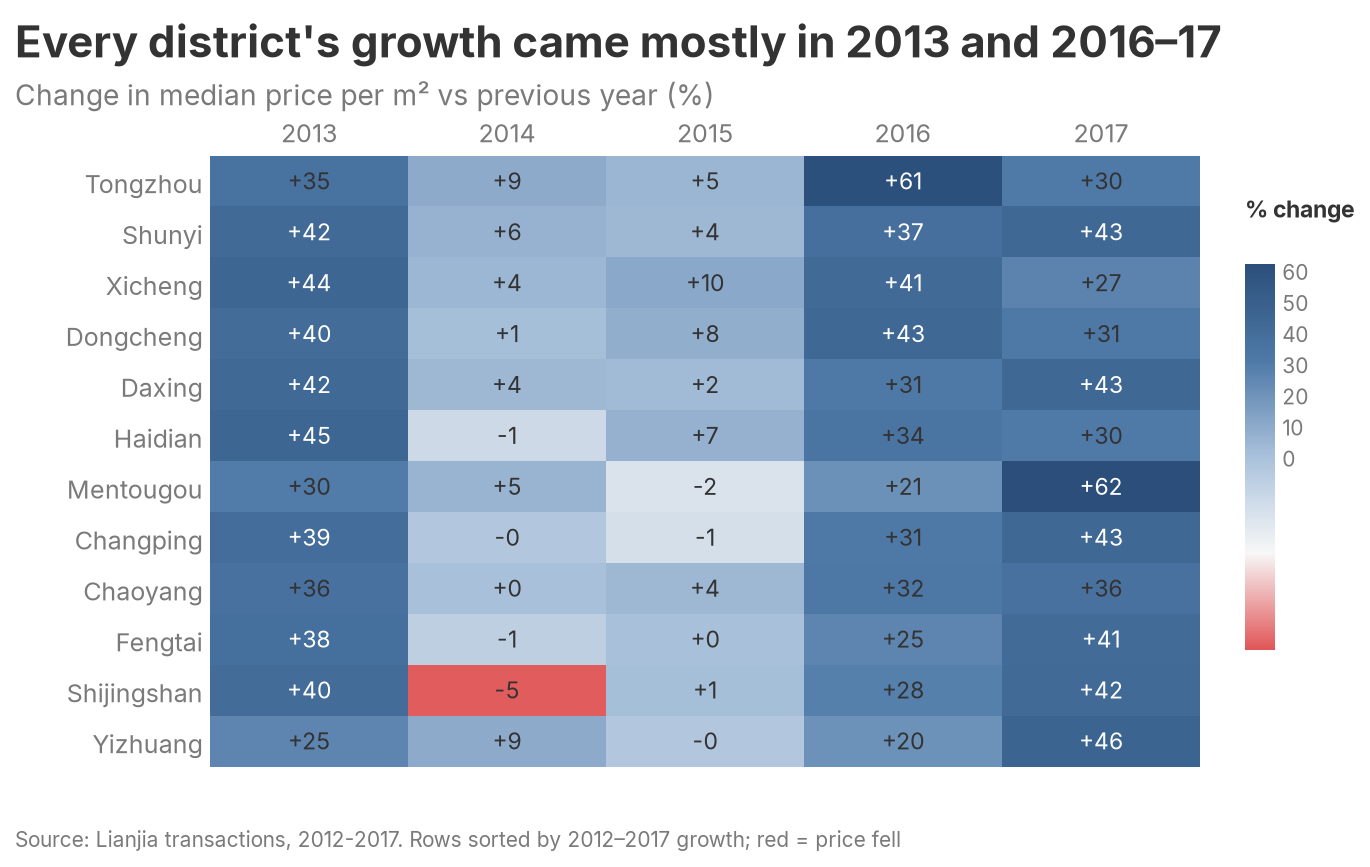

In [21]:
yoy_d = (dist_year.pct_change(axis=1) * 100).loc[dcagr.index[::-1], YEARS[1:]]
bursts = [yr for yr in yoy_d.columns if yoy_d[yr].median() > np.nanmean(yoy_d.values)]   # above-average years
burst_share = yoy_d[bursts].clip(lower=0).sum(axis=1) / yoy_d.clip(lower=0).sum(axis=1)
n_major = int((burst_share > 0.5).sum())
who = "Every district's" if n_major == len(yoy_d) else f"{n_major} of {len(yoy_d)} districts'"
print("burst years:", bursts, "| share of each district's gains in them:", burst_share.round(2).to_dict())
fig, ax = bs.new_chart(f"{who} growth came mostly in {year_ranges(bursts)}",
                       "Change in median price per m² vs previous year (%)", rect=(0.17, 0.12, 0.66, 0.70))
cmap = LinearSegmentedColormap.from_list("div", [bs.NEGATIVE, "#F7F7F7", "#A9C1DB", bs.HIGHLIGHT, "#2B4F7A"])
vmin, vmax = min(-1.0, np.floor(np.nanmin(yoy_d.values))), max(1.0, np.ceil(np.nanmax(yoy_d.values)))
im = ax.imshow(yoy_d.values, cmap=cmap, norm=TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax), aspect="auto")
for i in range(yoy_d.shape[0]):
    for j in range(yoy_d.shape[1]):
        v = yoy_d.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=11, color="white" if v > vmax * 0.6 else bs.INK)
ax.set_xticks(range(yoy_d.shape[1]), [str(c) for c in yoy_d.columns])
ax.set_yticks(range(yoy_d.shape[0]), yoy_d.index)
ax.tick_params(length=0)
ax.xaxis.tick_top()
for s_ in ax.spines.values():
    s_.set_visible(False)
cax = fig.add_axes([0.86, 0.25, 0.02, 0.45])
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10, length=0)
fig.text(0.86, 0.73, "% change", fontsize=11, fontweight="bold")
publish(fig, "PD2_district_growth_by_year.png", SRC + f". Rows sorted by {BASE}–{END} growth; red = price fell")

**PD3. Does the ranking change when comparing similar property types and sizes?**
Like-for-like = the most common size + building-type combination in the data, which removes differences in product mix.

like-for-like segment: 50–90 m², plate (90,993 trades)
                   all       like  r_all  r_like
dname                                           
Tongzhou     26.534535  26.139695      1       1
Shunyi       25.061805  25.122992      2       2
Xicheng      24.300117  23.537266      3       3
Dongcheng    23.321200  22.956584      4       4
Daxing       23.186063  22.689390      5       5
Haidian      21.632366  21.381503      6       7
Mentougou    21.331045  21.688841      7       6
Changping    20.660984  20.079437      8      10
Chaoyang     20.404785  20.184524      9       9
Fengtai      19.503599  19.512891     10      11
Shijingshan  19.424467  19.386758     11      12
Yizhuang     19.131979  20.261762     12       8


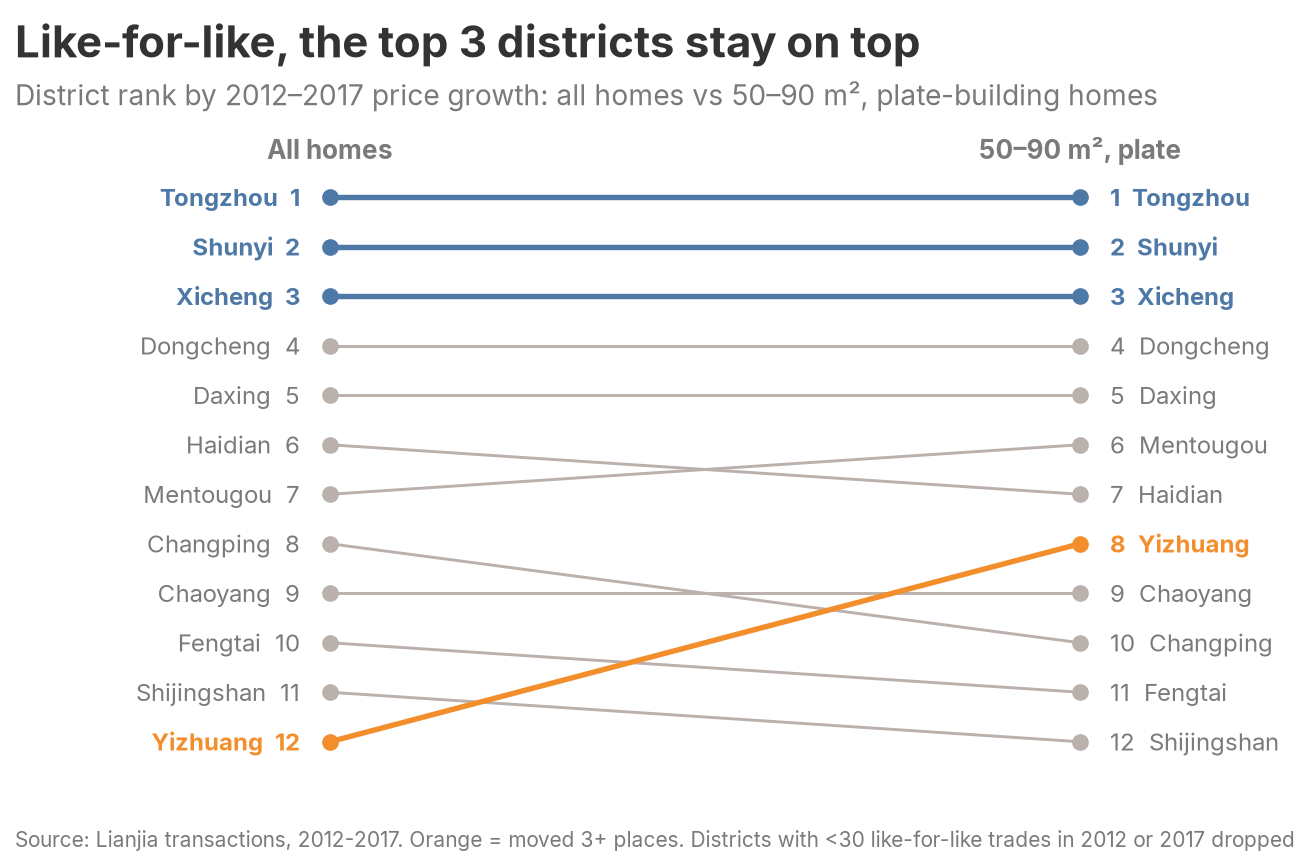

In [22]:
combo = df.groupby(["size_category", "btype"]).size().idxmax()
combo_lab = f"{SIZE_MAP[combo[0]]}, {combo[1].lower()}"
like = df[(df.size_category == combo[0]) & (df.btype == combo[1])]
ly = like.groupby(["dname", "trade_year"]).price.median().unstack()
ln = like.groupby(["dname", "trade_year"]).size().unstack()
ok_l = (ln[[BASE, END]].min(axis=1) >= 30) & valid
lcagr = ((ly[END] / ly[BASE]) ** (1 / N_YRS) - 1)[ok_l] * 100
both = pd.DataFrame({"all": dcagr, "like": lcagr}).dropna()
both["r_all"] = both["all"].rank(ascending=False, method="first").astype(int)
both["r_like"] = both["like"].rank(ascending=False, method="first").astype(int)
print(f"like-for-like segment: {combo_lab} ({len(like):,} trades)")
print(both.sort_values("r_all"))
moved = both[(both.r_all - both.r_like).abs() >= 3].index
top_all, top_like = set(both.index[both.r_all <= 3]), set(both.index[both.r_like <= 3])
pd3_title = ("Like-for-like, the top 3 districts stay on top" if top_all == top_like
             else f"Like-for-like, {join_names(sorted(top_like - top_all))} move into the top 3")
fig, ax = bs.new_chart(pd3_title, f"District rank by {BASE}–{END} price growth: all homes vs {combo_lab}-building homes",
                       rect=(0.24, 0.12, 0.52, 0.66))
for d_, r in both.iterrows():
    c = bs.HIGHLIGHT if r.r_all <= 3 else (bs.HIGHLIGHT_2 if d_ in moved else bs.CONTEXT)
    lw = 2.6 if c != bs.CONTEXT else 1.4
    ax.plot([0, 1], [r.r_all, r.r_like], color=c, lw=lw, marker="o", ms=7)
    ax.text(-0.04, r.r_all, f"{d_}  {int(r.r_all)}", ha="right", va="center", fontsize=11.5,
            color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold" if c != bs.CONTEXT else "normal")
    ax.text(1.04, r.r_like, f"{int(r.r_like)}  {d_}", ha="left", va="center", fontsize=11.5,
            color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold" if c != bs.CONTEXT else "normal")
ax.set_ylim(len(both) + 0.5, 0.5)
ax.set_xlim(-0.02, 1.02)
ax.set_xticks([0, 1], ["All homes", combo_lab], fontsize=12.5, fontweight="bold")
ax.xaxis.tick_top()
ax.set_yticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)
publish(fig, "PD3_district_rank_like_for_like.png",
        SRC + f". Orange = moved 3+ places. Districts with <30 like-for-like trades in {BASE} or {END} dropped")

**PD4. What sits behind district growth? (yearbook table 2-1, resident population)**

             cagr  popg
Changping    20.7  12.7
Chaoyang     20.4  -0.2
Daxing       23.2  19.8
Dongcheng    23.3  -6.3
Fengtai      19.5  -1.3
Haidian      21.6  -0.1
Mentougou    21.3   8.1
Shijingshan  19.4  -4.2
Shunyi       25.1  18.4
Tongzhou     26.5  16.8
Xicheng      24.3  -5.2 
correlation 0.46


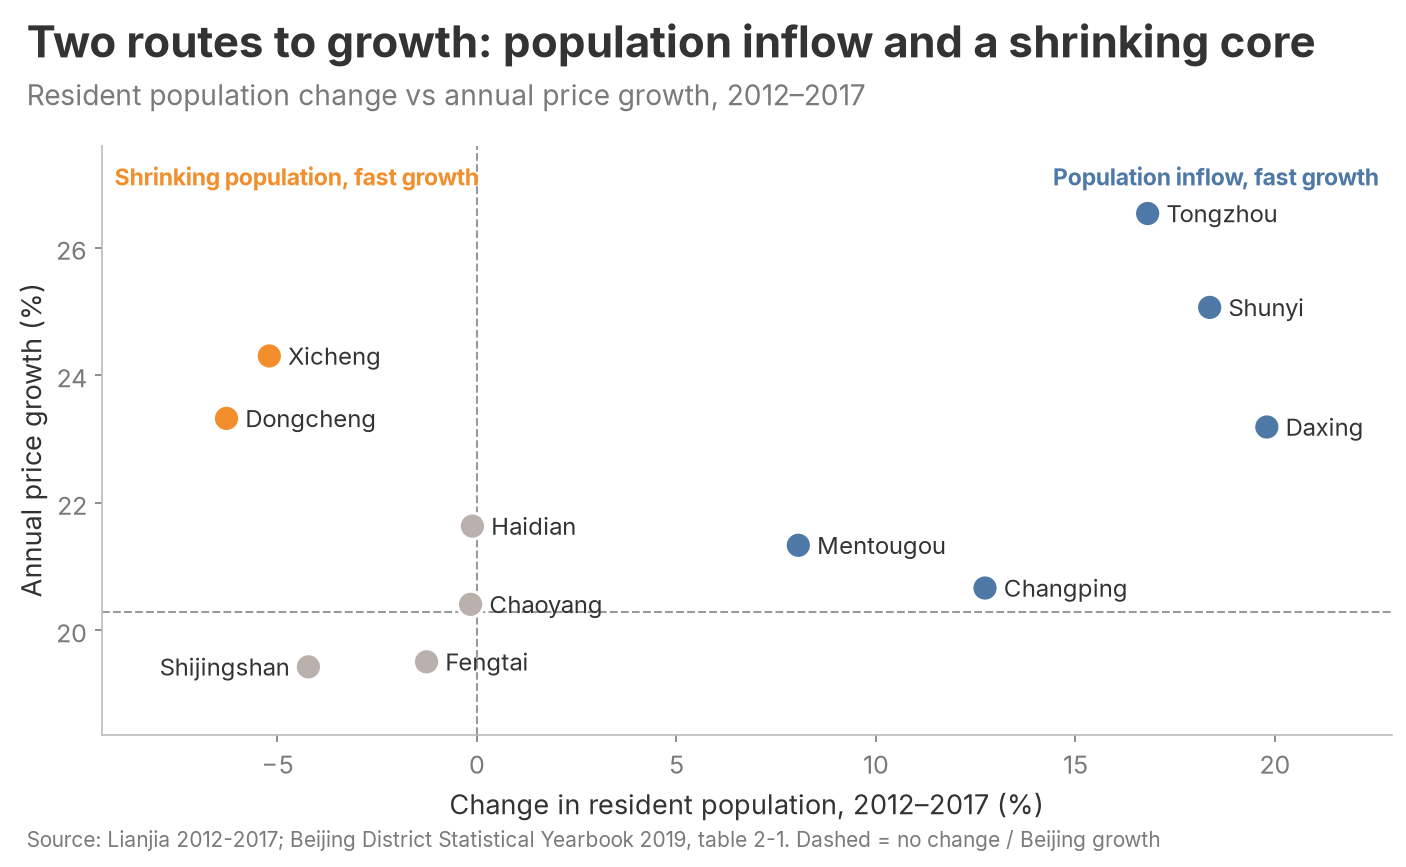

In [23]:
fund = pd.DataFrame({"cagr": dcagr, "popg": (pop[str(END)] / pop[str(BASE)] - 1) * 100}).dropna()
corr = fund.corr().iloc[0, 1]
print(fund.round(1), "\ncorrelation", round(corr, 2))
fast = fund.cagr > overall_cagr * 100
FLAT = 1.0                                   # population change within ±1% counts as flat
inflow, scarce = fast & (fund.popg > FLAT), fast & (fund.popg < -FLAT)
pd4_title = ("Two routes to growth: population inflow and a shrinking core" if inflow.any() and scarce.any()
             else f"Population change and price growth: correlation {corr:.2f}")
fig, ax = bs.new_chart(pd4_title, f"Resident population change vs annual price growth, {BASE}–{END}")
cols = [bs.HIGHLIGHT if i else (bs.HIGHLIGHT_2 if s else bs.CONTEXT) for i, s in zip(inflow, scarce)]
ax.scatter(fund.popg, fund.cagr, s=160, color=cols, edgecolor="white", lw=1.5, zorder=3)
ax.axvline(0, color="#9A9A9A", lw=1, ls="--")
ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.set_xlim(*padded(fund.popg.min(), fund.popg.max(), 0.12, include=[0]))
ax.set_ylim(*padded(fund.cagr.min(), fund.cagr.max(), 0.15, include=[overall_cagr * 100]))
ax.text(0.99, 0.97, "Population inflow, fast growth", transform=ax.transAxes, ha="right", va="top", fontsize=11,
        color=bs.HIGHLIGHT, fontweight="bold")
ax.text(0.01, 0.97, "Shrinking population, fast growth", transform=ax.transAxes, ha="left", va="top", fontsize=11,
        color=bs.HIGHLIGHT_2, fontweight="bold")
place_labels(ax, fund.popg, fund.cagr, fund.index, size=160)
ax.set_xlabel(f"Change in resident population, {BASE}–{END} (%)")
ax.set_ylabel("Annual price growth (%)")
publish(fig, "PD4_population_vs_growth.png",
        f"Lianjia {BASE}-{END}; Beijing District Statistical Yearbook 2019, table 2-1. Dashed = no change / Beijing growth")

## R. Risk: stability and liquidity
**R1. Which districts and property types have the most stable price trends?**
Volatility = standard deviation of quarter-on-quarter change in median price per m², 2012-2017.

age-band volatility spread 0.16 pp -> left out (bands are near-identical)


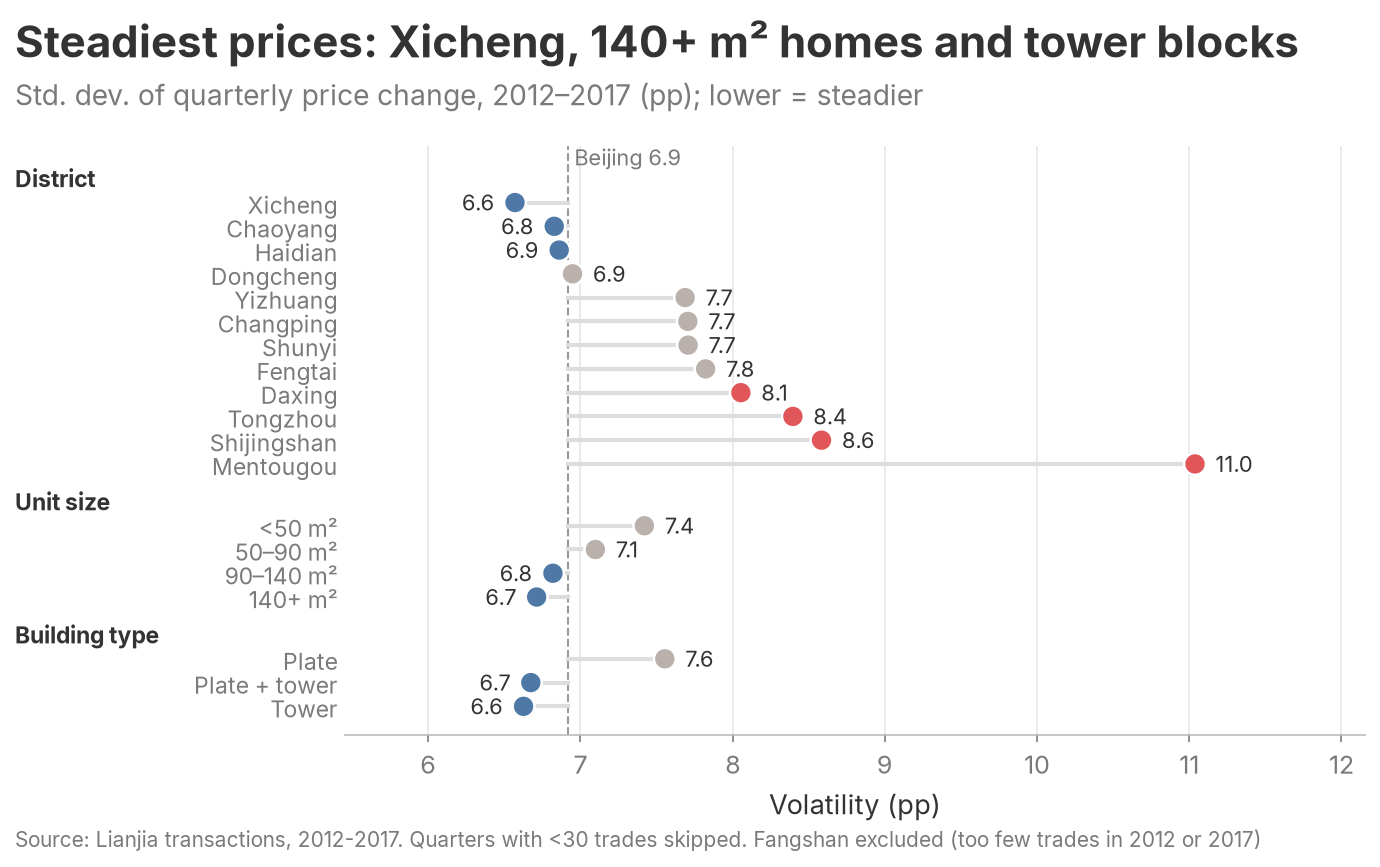

In [24]:
def volatility(col, data=df, min_n=30):
    q = data.groupby([col, "quarter"], observed=True).price.agg(["median", "size"])
    q = q[q["size"] >= min_n]["median"].unstack()
    return q.pct_change(axis=1).std(axis=1) * 100


vol_d = volatility("dname")
vol_d = vol_d[vol_d.index.isin(dcagr.index)]
vol_vals = {}
for col in ["size_lab", "btype", "age_lab"]:
    vol_vals.update(volatility(col).to_dict())
vol_vals.update(vol_d.to_dict())
city_vol = df.groupby("quarter").price.median().pct_change().std() * 100
vol_groups = [("District", list(vol_d.sort_values().index)), ("Unit size", SIZE_ORDER), ("Building type", BTYPES)]
age_spread = max(vol_vals[a] for a in AGE_ORDER) - min(vol_vals[a] for a in AGE_ORDER)
if age_spread >= 0.5:
    vol_groups.append(("Building age", AGE_ORDER))
print(f"age-band volatility spread {age_spread:.2f} pp -> {'shown' if age_spread >= 0.5 else 'left out (bands are near-identical)'}")
steady = {head: min(labs, key=vol_vals.get) for head, labs in vol_groups}
grouped_dots(vol_groups, vol_vals,
             f"Steadiest prices: {steady['District']}, {steady['Unit size']} homes and {phrase(steady['Building type'])} blocks",
             f"Std. dev. of quarterly price change, {BASE}–{END} (pp); lower = steadier",
             "Volatility (pp)", "R1_price_volatility.png", ref=city_vol, ref_label=f"Beijing {city_vol:.1f}",
             fmt="{:.1f}", colour_rule=lambda v: bs.NEGATIVE if v > city_vol * 1.15 else (bs.HIGHLIGHT if v < city_vol else bs.CONTEXT),
             src=SRC + ". Quarters with <30 trades skipped. " + EXCL_TXT)

**R2. Which districts face the greatest resale liquidity risk? (2017)**
Median DOM = a typical sale; 75th percentile DOM = the slow quarter of sales (tail risk).

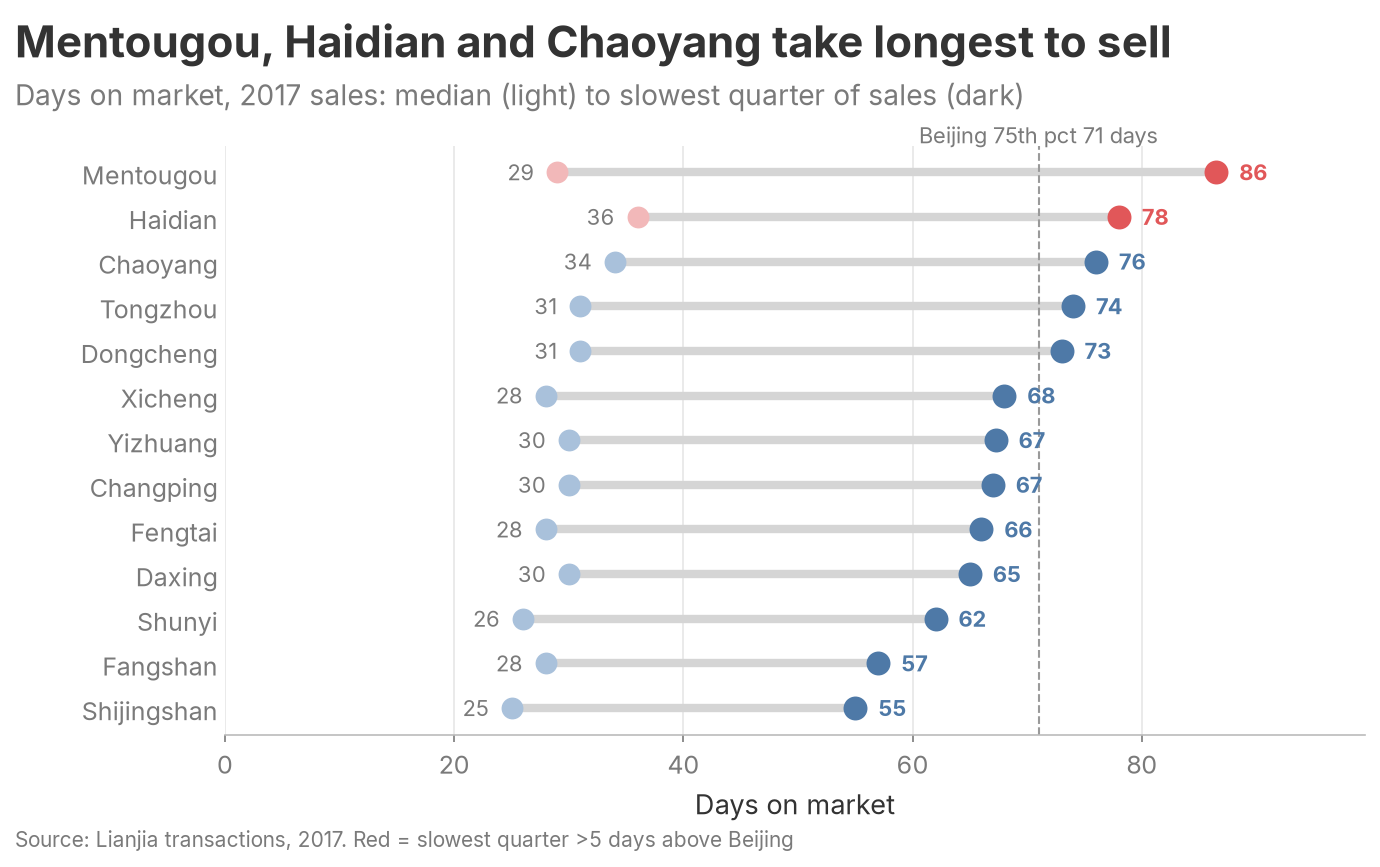

In [25]:
d17d = df[(df.trade_year == END) & df.DOM.notna()]


def dom_stats(col):
    return d17d.groupby(col, observed=True).DOM.agg(med="median", p75=lambda s: s.quantile(0.75), n="size")


dd = dom_stats("dname").sort_values("p75")
city_p75 = d17d.DOM.quantile(0.75)
fig, ax = bs.new_chart(f"{join_names(list(dd.index[::-1][:3]))} take longest to sell",
                       f"Days on market, {END} sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.18, 0.13, 0.76, 0.68))
for i, (d_, r) in enumerate(dd.iterrows()):
    risky = r.p75 > city_p75 + 5
    c = bs.NEGATIVE if risky else bs.HIGHLIGHT
    ax.plot([r.med, r.p75], [i, i], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(r.med, i, s=90, color="#A9C1DB" if not risky else "#F2B8B9", zorder=3)
    ax.scatter(r.p75, i, s=110, color=c, zorder=3)
    ax.text(r.p75 + 2, i, f"{r.p75:.0f}", va="center", fontsize=10.5, color=c, fontweight="bold")
    ax.text(r.med - 2, i, f"{r.med:.0f}", va="center", ha="right", fontsize=10.5, color=bs.MUTED)
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, len(dd) - 0.35, f"Beijing 75th pct {city_p75:.0f} days", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_yticks(range(len(dd)), dd.index)
ax.set_xlim(0, dd.p75.max() * 1.15)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
publish(fig, "R2_dom_by_district.png", f"Lianjia transactions, {END}. Red = slowest quarter >5 days above Beijing")

**R3. Which property types sell fastest / face the most liquidity risk? (2017)**

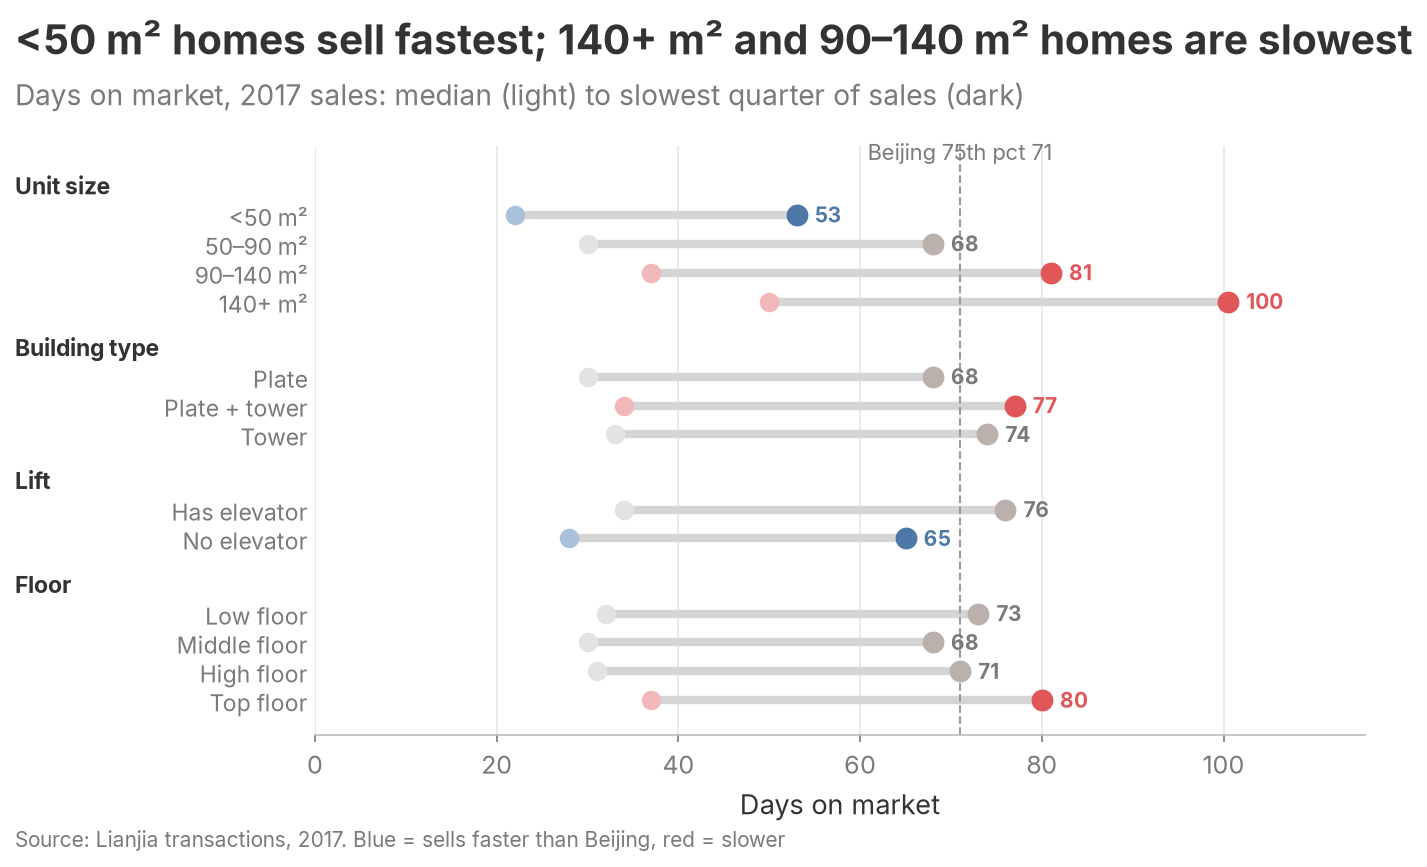

In [26]:
seg_groups = [("Unit size", SIZE_ORDER), ("Building type", BTYPES),
              ("Lift", ["Has elevator", "No elevator"]),
              ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]   # age and subway: see checks table
seg = pd.concat([dom_stats(c) for c in ["size_lab", "age_lab", "btype", "subway_lab", "elev_lab", "floor_lab"]])
rows, heads, yc = [], [], 0
for head, labs in seg_groups:
    heads.append((yc, head)); yc += 1
    for lab in labs:
        rows.append((yc, lab, seg.loc[lab, "med"], seg.loc[lab, "p75"])); yc += 1
    yc += 0.6
shown = pd.Series({lab: p75 for _, lab, _, p75 in rows}).sort_values()
fig, ax = bs.new_chart(f"{shown.index[0]} homes sell fastest; {join_names([phrase(l) for l in shown.index[::-1][:2]])} "
                       "homes are slowest",
                       f"Days on market, {END} sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.24, 0.13, 0.70, 0.68))
for yy, lab, med, p75 in rows:
    risky, fast_ = p75 > city_p75 + 5, p75 < city_p75 - 5
    c = bs.NEGATIVE if risky else (bs.HIGHLIGHT if fast_ else bs.CONTEXT)
    ax.plot([med, p75], [yy, yy], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(med, yy, s=70, color="#E3E3E3" if c == bs.CONTEXT else ("#F2B8B9" if risky else "#A9C1DB"), zorder=3)
    ax.scatter(p75, yy, s=90, color=c, zorder=3)
    ax.text(p75 + 2, yy, f"{p75:.0f}", va="center", fontsize=10, color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold")
ax.set_yticks([r[0] for r in rows], [r[1] for r in rows])
tr = blended_transform_factory(fig.transFigure, ax.transData)
for yh, head in heads:
    ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, -0.9, f"Beijing 75th pct {city_p75:.0f}", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_ylim(yc - 0.4, -1.4)
ax.set_xlim(0, shown.max() * 1.15)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
publish(fig, "R3_dom_by_segment.png", f"Lianjia transactions, {END}. Blue = sells faster than Beijing, red = slower")

**R4. Which districts offer the strongest appreciation relative to these risks?**

             cagr   p75   vol
dname                        
Yizhuang     19.1  67.2   7.7
Shijingshan  19.4  55.0   8.6
Fengtai      19.5  66.0   7.8
Chaoyang     20.4  76.0   6.8
Changping    20.7  67.0   7.7
Mentougou    21.3  86.5  11.0
Haidian      21.6  78.0   6.9
Daxing       23.2  65.0   8.1
Dongcheng    23.3  73.0   6.9
Xicheng      24.3  68.0   6.6
Shunyi       25.1  62.0   7.7
Tongzhou     26.5  74.0   8.4


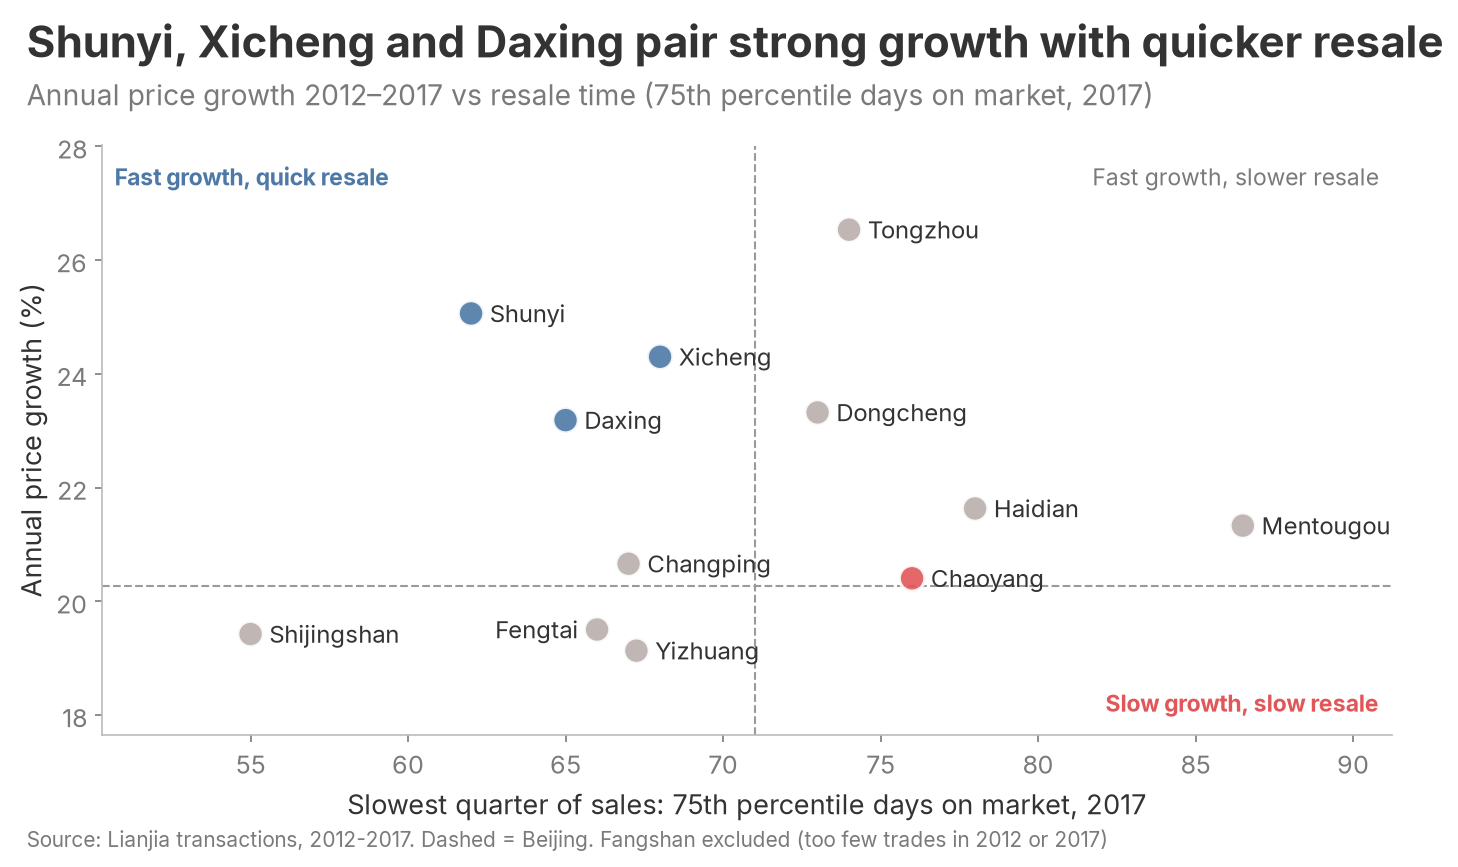

In [27]:
rr = pd.DataFrame({"cagr": dcagr, "p75": dd.p75, "vol": vol_d}).dropna()
print(rr.round(1).sort_values("cagr"))
xm, ym = city_p75, overall_cagr * 100
good = (rr.cagr > ym + 1) & (rr.p75 <= xm)
bad = (rr.cagr <= ym + 1) & (rr.p75 > xm)
good_names = list(rr[good].sort_values("cagr", ascending=False).index)
fig, ax = bs.new_chart(f"{join_names(good_names)} pair strong growth with quicker resale" if good_names
                       else "No district pairs strong growth with quick resale",
                       f"Annual price growth {BASE}–{END} vs resale time (75th percentile days on market, {END})")
cols = [bs.HIGHLIGHT if g_ else (bs.NEGATIVE if b_ else bs.CONTEXT) for g_, b_ in zip(good, bad)]
ax.scatter(rr.p75, rr.cagr, s=150, color=cols, alpha=0.9, edgecolor="white", lw=1.5, zorder=3)
ax.axvline(xm, color="#9A9A9A", lw=1, ls="--")
ax.axhline(ym, color="#9A9A9A", lw=1, ls="--")
ax.set_xlim(*padded(rr.p75.min(), rr.p75.max(), 0.15, include=[xm]))
ax.set_ylim(*padded(rr.cagr.min(), rr.cagr.max(), 0.2, include=[ym]))
q = dict(transform=ax.transAxes, fontsize=11)
ax.text(0.01, 0.97, "Fast growth, quick resale", ha="left", va="top", color=bs.HIGHLIGHT, fontweight="bold", **q)
ax.text(0.99, 0.97, "Fast growth, slower resale", ha="right", va="top", color=bs.MUTED, **q)
ax.text(0.99, 0.03, "Slow growth, slow resale", ha="right", va="bottom", color=bs.NEGATIVE, fontweight="bold", **q)
place_labels(ax, rr.p75, rr.cagr, rr.index)
ax.set_xlabel(f"Slowest quarter of sales: 75th percentile days on market, {END}")
ax.set_ylabel("Annual price growth (%)")
publish(fig, "R4_growth_vs_liquidity_risk.png", SRC + ". Dashed = Beijing. " + EXCL_TXT)

**R5. Affordability stretch: how many months of local income does 1 m² cost? (yearbook 2-14)**

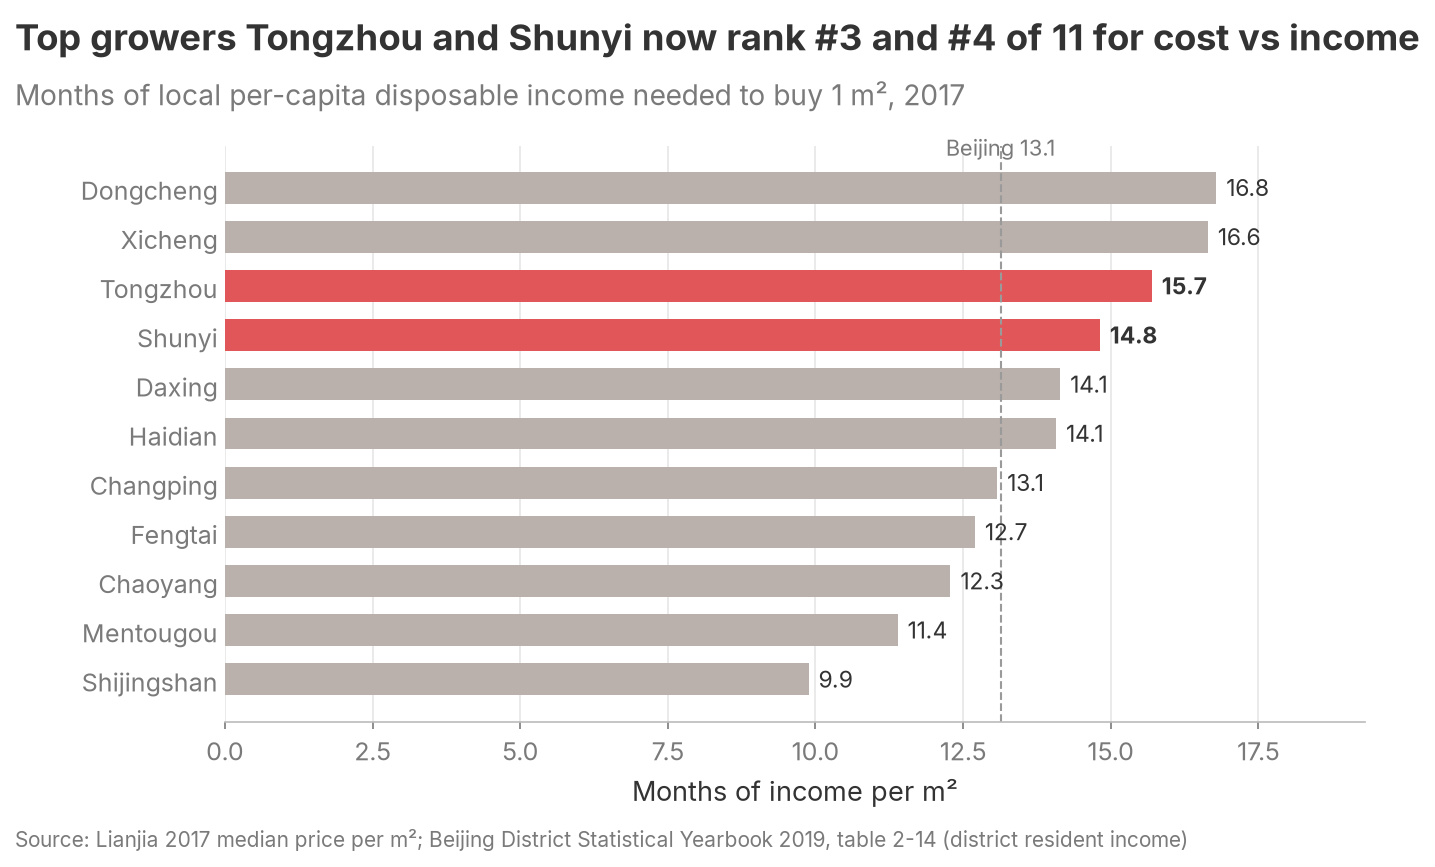

In [28]:
aff = (dist_year[END] / (income[str(END)] / 12)).dropna()
aff = aff[aff.index.isin(dcagr.index)].sort_values()
city_aff = yearly[END] / (income.loc["Beijing", str(END)] / 12)
growers = list(dcagr.nlargest(2).index)
rank = aff.rank(ascending=False, method="first").astype(int)
fig, ax = bs.new_chart(f"Top growers {join_names(growers)} now rank "
                       f"{join_names([f'#{rank[d]}' for d in growers])} of {len(aff)} for cost vs income",
                       f"Months of local per-capita disposable income needed to buy 1 m², {END}", rect=(0.18, 0.17, 0.76, 0.64))
cols = [bs.NEGATIVE if d_ in growers else bs.CONTEXT for d_ in aff.index]
ax.barh(aff.index, aff.values, color=cols, height=0.65)
for i, v in enumerate(aff.values):
    ax.text(v + aff.max() * 0.01, i, f"{v:.1f}", va="center", fontsize=11, fontweight="bold" if cols[i] == bs.NEGATIVE else "normal")
ax.axvline(city_aff, color="#9A9A9A", lw=1, ls="--")
ax.text(city_aff, len(aff) - 0.35, f"Beijing {city_aff:.1f}", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(0, aff.max() * 1.15)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Months of income per m²")
bs.xgrid(ax)
publish(fig, "R5_affordability.png",
        f"Lianjia {END} median price per m²; Beijing District Statistical Yearbook 2019, table 2-14 (district resident income)")

## Numbers behind the charts (for validation)

In [29]:
checks = {
    "district_check": check,
    "district_growth": pd.DataFrame({"cagr_pct": dcagr}).join(dist_n),
    "district_dom_2017": dd,
    "segment_dom_2017": seg,
    "district_volatility": vol_d.rename("volatility_pp").to_frame(),
    "followers_size_age_2017": fol,
    "monthly": monthly,
    "premium_vs_growth": P,
    "rank_like_for_like": both,
    "population_vs_growth": fund,
    "growth_vs_risk": rr,
    "affordability": aff.rename("months_income_per_m2").to_frame(),
    "growth_drivers": R,
}
with pd.ExcelWriter(OUT / "checks_all_charts.xlsx") as xw:
    for k, v in checks.items():
        v.to_excel(xw, sheet_name=k[:31])
print("saved", OUT / "checks_all_charts.xlsx")

saved charts_from_data\checks_all_charts.xlsx
